<img src="logo.png" alt="Vegeta" width="240">

# Svarog — from a rod to the 1 kW and 2 kW welding lasers and their guard, in one notebook

The Svarog series in one place, **per topic**: Part I the end-pumped Nd:YAG rod (the thermal lens, Magni's rule — where
pumping, heat and modes are learnt); Part II the Yb fibre oscillator and amplifier (the architecture the devices use);
Part III the industrial lasers — the **1 kW** and the **2 kW** analysed one after the other in every topic on the same code
(`si.Device`): the power stage, the heat budget, the process fibre and head, the welds; Part IV their guard — the stray
beams, the eleven barriers, the collimated beam against distance on the reference 2 mm polycarbonate sheet, what the air
takes, and book fenix's finite-element runs against the cell model; Part V the record. Everything is Hyperion
(`vegeta.hyperion`, [docs/hyperion.md](../docs/hyperion.md); the physics and solvers in
[docs/svarog_physics.md](../docs/svarog_physics.md), [docs/svarog_solvers.md](../docs/svarog_solvers.md)); the design
modules `designs/svarog*.py`. The fenix runs (F1–F3, 1kW and 2kW) are optional inputs: Yanus auto mode makes them in
screening quality when the fenicsx interpreter exists; otherwise their tables say NOT RUN. Without them: minutes.

In [1]:
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, "designs")
from vegeta import hyperion as hy
from vegeta.hyperion import fibre as fb, welding as wd, thermal as th
import svarog as sv, svarog_drawings as svd
import svarog_fiber as sf, svarog_fiber_drawings as sfd
import svarog_industrial as si, svarog_industrial_drawings as sid

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 240)
DATA = Path("designs/data")
OUT = Path("output/46_svarog"); OUT.mkdir(parents=True, exist_ok=True)
from vegeta import yanus
GATE = yanus.enter("46_svarog", debug=DEBUG)        # the door keeper: needs vegeta.hyperion; takes the fenix runs (optional); gives the records
PUMP_DESIGN = 20.0                                  # Part I: W incident on the rod, its work point
PUMP_OSC, PUMP_AMP = 20.0, 50.0                     # Part II: W launched into the oscillator and the amplifier

# Part I — the rod

**Svarog** is a 1064 nm continuous-wave laser: a Ø3 × 10 mm Nd:YAG rod pumped end-on at 808 nm by a 30 W fibre-coupled
diode, in a cavity whose mirrors, spacings and output coupler this notebook chooses. Everything is computed with
**Hyperion** (`vegeta.hyperion`, [docs/hyperion.md](../docs/hyperion.md)): the pump imaged onto the rod and its radius
inside it, the four-level laser's threshold, slope and output, the pump's thermal lens, the cavity's eigenmode and
stability window over the pump power — re-solved at every pump power, since the lens moves with it — the beam that leaves
the coupler and the lens train that puts it on a work spot. The device as numbers is `designs/svarog.py` (`import svarog as sv`);
the drawings are `designs/svarog_drawings.py`.

Four cavity revisions are compared at the 20 W design pump: **A** the textbook plano–concave layout, **B** a compact
cavity with the HR coating on the rod's face, **C** a folded cavity with a concave fold mirror at an angle, **D** a
zone-II cavity that is unstable cold and opens above 13 W. The record goes to `designs/data/svarog_design.json` (the chosen
cavity, the beam, the delivery train as Hyperion objects) and `designs/data/reports/46_svarog.json`.

What is *not* here: apertures and diffraction, lens aberrations, the rod's real temperature field and stress, the mounts
and the build, pulses and frequency conversion — the roadmap of [`svarog_todo.md`](../svarog_todo.md), in the order it is needed.

In [3]:
OUT = Path("output/46_svarog"); OUT.mkdir(parents=True, exist_ok=True)

### 1. The rod and its pump

The medium's numbers (Koechner's for 1 at.% Nd:YAG), the rod, how much of the pump it absorbs and where the heat sits
(the absorption-weighted centroid, 2.3 mm in). The pump: a 200 µm-core, NA 0.22 fibre, whose beam has M² = π r NA/λ ≈ 85,
imaged onto the rod's entrance face by a 25 mm collimator and a focusing lens. The spot on the face is the core radius
times the magnification; inside the rod the beam diverges at NA/n and its radius grows along the absorption length — the
*effective* pump radius (the absorption-weighted mean of w_p²) is what the gain and the thermal lens see. The table over the
magnification shows the trade: a small spot on the face is a large effective radius (the beam diverges before it is absorbed);
beyond M ≈ 4 the effective radius is the face spot. Magni's rule gives the largest TEM₀₀ mode a cavity that stays stable from
0 to 30 W can hold, w² = 2λ/(π ΔD), where ΔD is the dioptric swing of the thermal lens over that range: a larger pump spot
means a weaker lens and a larger mode cap.

medium                      Nd:YAG 1.0 at.%
σ [cm²]                             2.8e-19
τ [µs]                                230.0
λ laser [nm]                         1064.0
λ pump [nm]                           808.0
α pump [1/cm]                           4.0
η_q                                     0.9
η_heat                                  0.3
n (1064)                           1.814653
dn/dT [1/K]                         7.3e-06
κ [W/m/K]                              13.0
I_sat [kW/cm²]                     2.899007
rod Ø × L [mm]                       3 × 10
pump absorbed                      0.981684
absorption centroid [mm]           2.313426
Name: Svarog's rod, dtype: object

pump fibre: core radius 100 µm, NA 0.22, M² 86; collimator f 25 mm, focusing lens f 100 mm: magnification 4.0


,spot on the face [µm],effective radius [µm],radius at the exit [µm],Rayleigh range in the rod [mm],thermal lens f at 20 W [mm],f at 30 W [mm],"Magni mode cap, 0–30 W window [µm]",threshold at that mode [W]
magnification,,,,,,,,
1.5,150.0,293.9,821.7,1.9,68.4,45.6,175.7,0.4
2.0,200.0,277.2,641.3,3.3,60.8,40.5,165.7,0.4
3.0,300.0,328.9,512.8,7.4,85.6,57.1,196.7,0.6
4.0,400.0,415.1,516.2,13.2,136.4,90.9,248.2,0.9
5.0,500.0,510.1,572.8,20.6,205.9,137.3,304.9,1.3
6.0,600.0,607.8,651.7,29.5,292.4,195.0,363.4,1.9


chosen: magnification 4 → 400 µm on the face, effective pump radius 415 µm


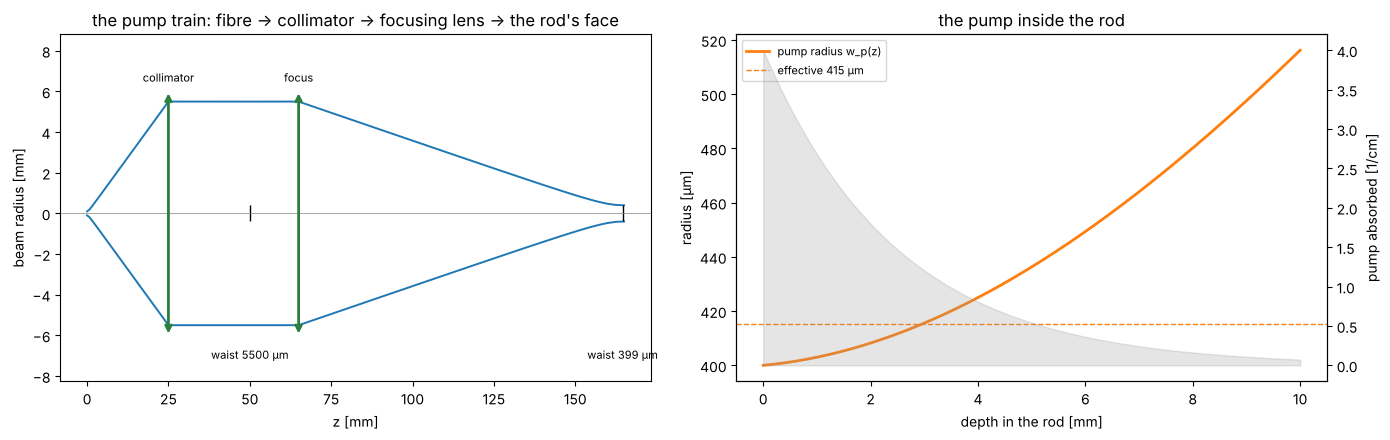

In [4]:
m = sv.ROD.medium
display(pd.Series({"medium": m.name, "σ [cm²]": f"{m.sigma * 1e4:.1e}", "τ [µs]": m.tau * 1e6, "λ laser [nm]": m.wavelength * 1e9, "λ pump [nm]": m.pump_wavelength * 1e9,
                   "α pump [1/cm]": m.alpha_pump / 100, "η_q": m.eta_q, "η_heat": m.eta_heat, "n (1064)": m.n(), "dn/dT [1/K]": f"{m.material.dn_dT:.1e}",
                   "κ [W/m/K]": m.material.kappa, "I_sat [kW/cm²]": m.saturation_intensity / 1e7,
                   "rod Ø × L [mm]": f"{2 * sv.ROD.radius * 1e3:.0f} × {sv.ROD.length * 1e3:.0f}", "pump absorbed": sv.ROD.absorbed_fraction,
                   "absorption centroid [mm]": sv.absorption_centroid() * 1e3}, name="Svarog's rod"))
fibre = sv.PUMP.beam()
print(f"pump fibre: core radius {sv.PUMP.core_radius * 1e6:.0f} µm, NA {sv.PUMP.NA}, M² {fibre.m2:.0f}; collimator f {sv.PUMP.f_collimator * 1e3:.0f} mm, "
      f"focusing lens f {sv.PUMP.f_focus * 1e3:.0f} mm: magnification {sv.PUMP.magnification:.1f}")
rows = {}
for M in (1.5, 2, 3, 4, 5, 6):
    p = sv.pump_in_rod(sv.PUMP.with_magnification(M))
    f30 = sv.thermal_lens(sv.PUMP.power_max, p["w_effective"]).f
    cap = math.sqrt(2 * sv.LAM / (math.pi / f30))
    rows[M] = {"spot on the face [µm]": p["w_face"] * 1e6, "effective radius [µm]": p["w_effective"] * 1e6, "radius at the exit [µm]": p["w_exit"] * 1e6,
               "Rayleigh range in the rod [mm]": p["rayleigh_in_rod"] * 1e3, "thermal lens f at 20 W [mm]": sv.thermal_lens(PUMP_DESIGN, p["w_effective"]).f * 1e3,
               "f at 30 W [mm]": f30 * 1e3, "Magni mode cap, 0–30 W window [µm]": cap * 1e6,
               "threshold at that mode [W]": hy.Laser(sv.ROD, p["w_effective"], cap, 0.10, sv.LOSS_ROUND_TRIP).threshold()}
MAG = pd.DataFrame(rows).T; MAG.index.name = "magnification"
display(MAG.round(1))
PR = sv.pump_in_rod(sv.PUMP)
W_PUMP = PR["w_effective"]
print(f"chosen: magnification {sv.PUMP.magnification:.0f} → {PR['w_face'] * 1e6:.0f} µm on the face, effective pump radius {W_PUMP * 1e6:.0f} µm")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
svd.train_view(PR["trace"], ax=axs[0], title="the pump train: fibre → collimator → focusing lens → the rod's face", scale_w=1e3, unit="mm")
svd.pump_view(PR, sv.ROD, ax=axs[1])
plt.tight_layout(); plt.savefig(OUT / "pump.png", dpi=110); plt.show()

### 2. Threshold, slope, output and the coupler

The four-level steady state on the effective area π(w_p² + w_l²)/2 (Fan & Byer, Laporta & Brussard): the threshold pump
P_th = π hν_p (w_p² + w_l²)(T + L)/(4 σ τ η_abs η_q), the slope η_s = η_abs η_q (λ_p/λ_l) T/(T + L), the output η_s (P − P_th).
The mode radius is a placeholder here (Magni's cap from the table above); § 4 replaces it with the mode each cavity has. The
output coupler: the output against T at 20 W (a scan) against Rigrod's T_opt = √(g₀L) − L; with a 1.2 % round-trip loss and a
small-signal gain of several nepers the optimum is a strong coupler, and the curve is flat around it — 10 % is chosen,
a stock value that keeps the intracavity power (and the coatings' load) moderate.

,threshold [W],slope,output at 20 W [W],intracavity at 20 W [W]
T,,,,
0.03,0.333,0.479,9.425,314.169
0.05,0.492,0.541,10.555,211.106
0.08,0.730,0.583,11.242,140.530
0.10,0.889,0.599,11.448,114.484
0.15,1.286,0.621,11.626,77.506
0.20,1.683,0.633,11.594,57.970


optimum coupler at 20 W: T = 0.162 (Rigrod 0.162) for 11.63 W; small-signal gain g0 = 2.52 nepers per round trip; chosen T = 0.10


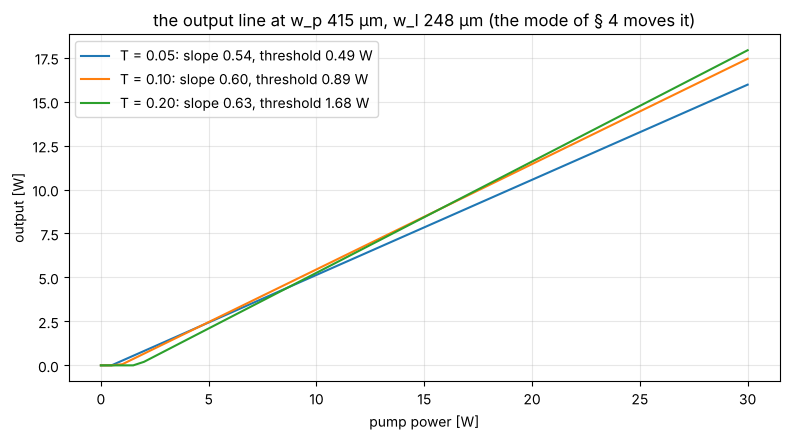

In [5]:
W_MODE_GUESS = float(MAG.loc[sv.PUMP.magnification, "Magni mode cap, 0–30 W window [µm]"]) * 1e-6
L0 = hy.Laser(sv.ROD, W_PUMP, W_MODE_GUESS, 0.10, sv.LOSS_ROUND_TRIP)
COUP = pd.DataFrame({T: {"threshold [W]": L0.threshold(T), "slope": L0.slope_efficiency(T), "output at 20 W [W]": float(L0.output(PUMP_DESIGN, T)),
                         "intracavity at 20 W [W]": L0.intracavity(PUMP_DESIGN, T)} for T in sv.T_CANDIDATES}).T
COUP.index.name = "T"; display(COUP.round(3))
OPT = L0.optimum_coupler(PUMP_DESIGN)
print(f"optimum coupler at {PUMP_DESIGN:.0f} W: T = {OPT['T_opt']:.3f} (Rigrod {OPT['T_opt_rigrod']:.3f}) for {OPT['P_out']:.2f} W; "
      f"small-signal gain g0 = {OPT['g0']:.2f} nepers per round trip; chosen T = 0.10")
pumps = np.linspace(0, sv.PUMP.power_max, 61)
fig, ax = plt.subplots(figsize=(8, 4.5))
for T in (0.05, 0.10, 0.20):
    ax.plot(pumps, L0.output(pumps, T), label=f"T = {T:.2f}: slope {L0.slope_efficiency(T):.2f}, threshold {L0.threshold(T):.2f} W")
ax.set_xlabel("pump power [W]"); ax.set_ylabel("output [W]"); ax.set_title(f"the output line at w_p {W_PUMP * 1e6:.0f} µm, w_l {W_MODE_GUESS * 1e6:.0f} µm (the mode of § 4 moves it)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig(OUT / "output_line.png", dpi=110); plt.show()

### 3. The thermal lens

Innocenti's end-pumped lens, 1/f = η_h P_abs (dn/dT)/(π κ w_p²), plus 20 % for the stress-induced index change and the
end-face bulging (the Nd:YAG literature's share; Hyperion takes it as a stated fraction, never a default). At the design
pump it is a lens of a few centimetres' focal length sitting 2.3 mm inside the rod — the element that decides the
cavity. The rod's centre-to-barrel temperature rise (steady radial conduction, the heat inside the pump radius) says how
hot the crystal runs; its fracture and depolarisation limits are stage S.2.

,heat [W],"f, dn/dT only [mm]",f with stress and bulge [mm],dioptres,ΔT centre–barrel [K]
pump [W],,,,,
5,1.47,654.77,545.64,1.83,3.22
10,2.95,327.38,272.82,3.67,6.43
15,4.42,218.26,181.88,5.50,9.65
20,5.89,163.69,136.41,7.33,12.87
25,7.36,130.95,109.13,9.16,16.09
30,8.84,109.13,90.94,11.00,19.30


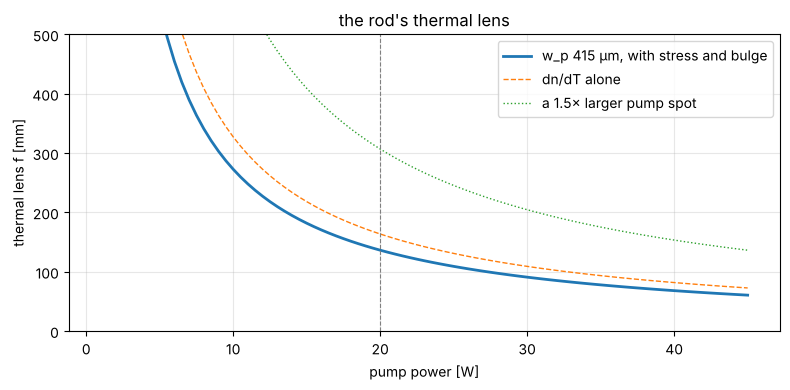

In [6]:
TL = pd.DataFrame({P: {"heat [W]": sv.ROD.medium.eta_heat * sv.ROD.absorbed_fraction * P, "f, dn/dT only [mm]": hy.thermal_lens(sv.ROD, P, W_PUMP).f * 1e3,
                       "f with stress and bulge [mm]": sv.thermal_lens(P, W_PUMP).f * 1e3, "dioptres": 1 / sv.thermal_lens(P, W_PUMP).f,
                       "ΔT centre–barrel [K]": hy.rod_temperature_rise(sv.ROD, P, W_PUMP)["dT_centre_to_barrel"]} for P in (5, 10, 15, 20, 25, 30)}).T
TL.index.name = "pump [W]"; display(TL.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
pp = np.linspace(1, 45, 89)
ax.plot(pp, [sv.thermal_lens(P, W_PUMP).f * 1e3 for P in pp], lw=2, label=f"w_p {W_PUMP * 1e6:.0f} µm, with stress and bulge")
ax.plot(pp, [hy.thermal_lens(sv.ROD, P, W_PUMP).f * 1e3 for P in pp], lw=1, ls="--", label="dn/dT alone")
ax.plot(pp, [sv.thermal_lens(P, 1.5 * W_PUMP).f * 1e3 for P in pp], lw=1, ls=":", label=f"a 1.5× larger pump spot")
ax.set_ylim(0, 500); ax.axvline(PUMP_DESIGN, color="grey", lw=0.8, ls="--")
ax.set_xlabel("pump power [W]"); ax.set_ylabel("thermal lens f [mm]"); ax.legend(); ax.grid(alpha=0.3); ax.set_title("the rod's thermal lens")
plt.tight_layout(); plt.savefig(OUT / "thermal_lens.png", dpi=110); plt.show()

### 4. The cavities on Hyperion

Each revision is a `Train` from the HR to the output coupler with the rod split at the absorption centroid around the
thermal lens; Hyperion solves the round trip for the self-reproducing Gaussian in both planes, puts its spot on every element
and sweeps the pump power for the stability window. The drawings show the mode envelope at the design pump; the table
compares the revisions there: the mode in the rod against the pump radius (a top-hat pump: the share inside the mode is
the square of the ratio — pump outside the TEM₀₀ mode feeds higher-order modes), the astigmatism of the folded cavity, the
window, the threshold and output, the spectrum, the beam out.

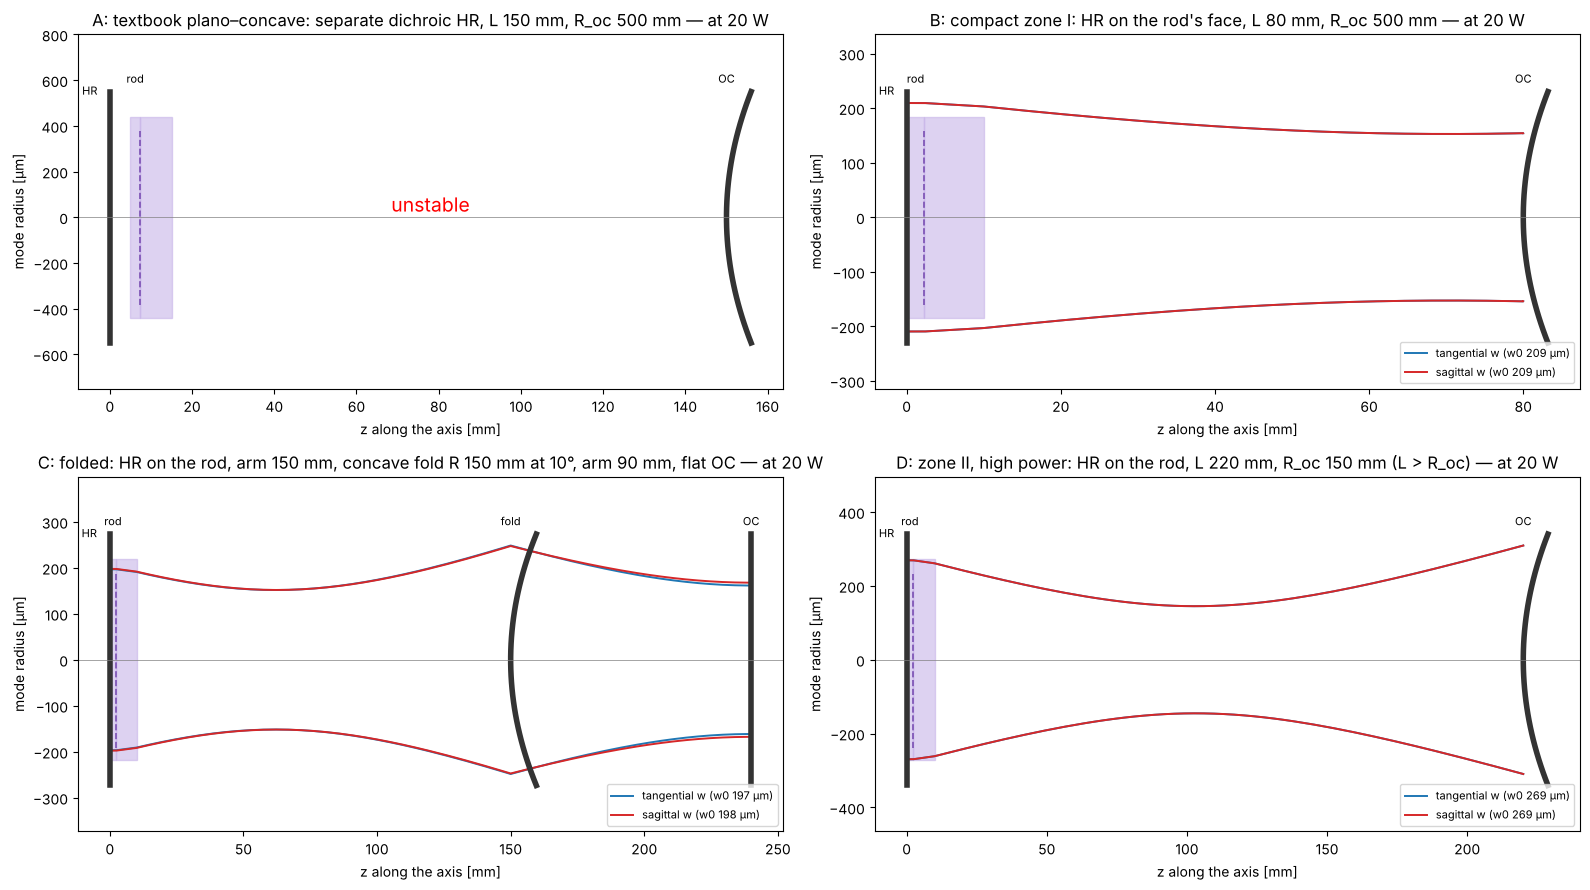

,title,length [mm],T,stable,mode in rod [µm],pump radius [µm],mode / pump,pump inside the mode,astigmatism w_t/w_s,spot on OC [µm],...,output [W],thermal lens f [mm],stable from 0 W,window from [W],window to [W],FSR [MHz],linewidth [MHz],modes under the gain line,beam out w0 [µm],beam out divergence [mrad]
A,"textbook plano–concave: separate dichroic HR, L 150 mm, R_oc 500 mm",150.0,0.1,False,NaN,415.135323,NaN,NaN,NaN,NaN,...,0.0,136.409737,True,NaN,NaN,947.83126,17.868559,126.604814,NaN,NaN
B,"compact zone I: HR on the rod's face, L 80 mm, R_oc 500 mm",80.0,0.1,True,209.369779,415.135323,0.504341,0.25436,1.0,154.124271,...,11.382857,136.409737,True,0.0,36.5,1700.534569,32.058557,70.566046,153.667,2.203998
C,"folded: HR on the rod, arm 150 mm, concave fold R 150 mm at 10°, arm 90 mm, flat OC",240.0,0.1,True,197.202708,415.135323,0.475032,0.225656,0.99554,161.453884,...,11.39412,136.409737,True,0.0,38.5,604.063358,11.484061,198.654658,161.453884,2.097699
D,"zone II, high power: HR on the rod, L 220 mm, R_oc 150 mm (L > R_oc)",220.0,0.1,True,269.390439,415.135323,0.648922,0.4211,1.0,309.316481,...,11.31743,136.409737,False,13.0,42.0,657.017339,12.386122,182.643582,214.763204,1.577001


In [7]:
fig, axs = plt.subplots(2, 2, figsize=(16, 9))
for ax, rev in zip(axs.flat, sv.REVISIONS.values()):
    svd.cavity_view(sv.cavity(rev, PUMP_DESIGN, W_PUMP), ax=ax, title=f"{rev.name}: {rev.title} — at {PUMP_DESIGN:.0f} W")
plt.tight_layout(); plt.savefig(OUT / "cavities.png", dpi=110); plt.show()
CMP = pd.DataFrame(sv.compare(sv.REVISIONS.values(), PUMP_DESIGN, W_PUMP))
display(CMP.T.rename(columns=lambda c: c))

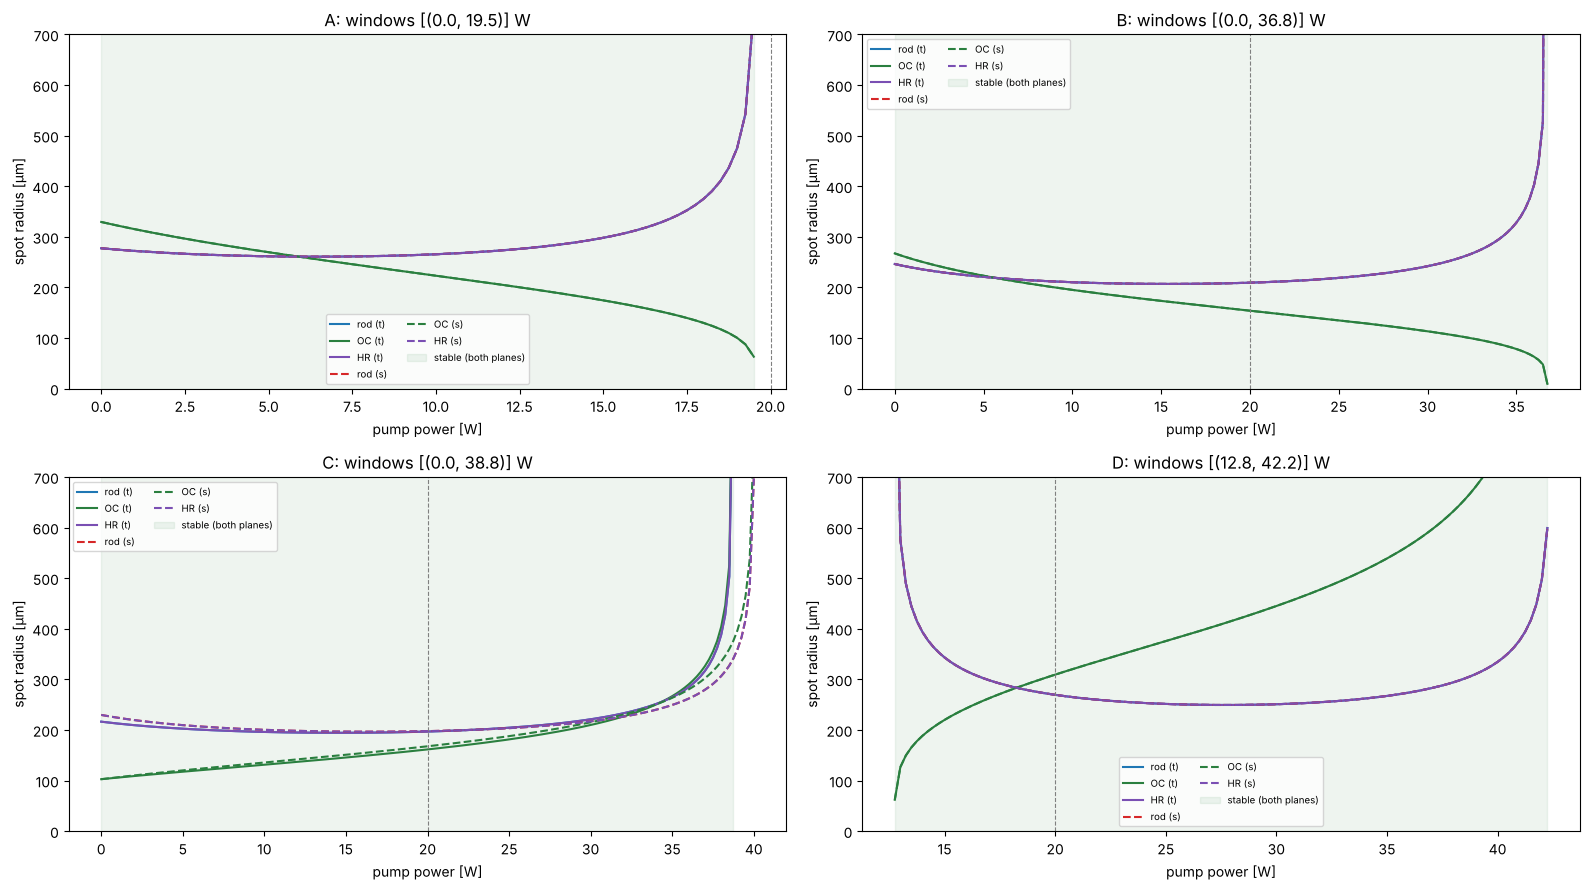

In [8]:
WIN = {name: sv.stability_window(rev, W_PUMP, np.linspace(0, 45, 181)) for name, rev in sv.REVISIONS.items()}
fig, axs = plt.subplots(2, 2, figsize=(16, 9))
for ax, (name, win) in zip(axs.flat, WIN.items()):
    svd.stability_view(win, ax=ax, title=f"{name}: windows {[(round(a, 1), round(b, 1) if b != math.inf else 'inf') for a, b in win['windows']]} W")
    ax.axvline(PUMP_DESIGN, color="grey", lw=0.8, ls="--"); ax.set_ylim(0, 700)
plt.tight_layout(); plt.savefig(OUT / "stability.png", dpi=110); plt.show()

**Reading the four.** The textbook cavity **A** is stable cold with a 280 µm mode — and closes at 19.5 W, before the
design pump: a long arm behind a lens of 136 mm focal length is past the concentric point. **B** and **C** are stable
from cold to beyond the diode's 30 W, but their mode in the rod is half the pump spot — Magni's rule: a window that spans the
whole dioptric swing of the lens (0 to 11 D) can only hold w² = 2λ/(π ΔD), ≈ 250 µm, whatever the mirrors; only a quarter
of the pump lies inside the TEM₀₀ mode, the rest feeds higher-order modes. **C** buys a nearly collimated second arm for the later Q-switch or doubling crystal
at the price of a 10° fold's astigmatism (a few per cent at this radius). **D** is the high-power design: with L > R_oc it is
unstable cold and the thermal lens opens it at 13 W; inside its window the mode is two thirds of the pump spot, 42 % of the
pump inside it (the window's dioptric width is what it holds), and it stays open to 42 W. Svarog takes **D** for the 15–30 W work range, with **B**
recorded as the fallback that lases at any pump. The output powers hardly differ — the threshold is a watt against twenty —
but the beam quality at the work spot does, and that is what the mode-to-pump ratio buys.

In [9]:
CHOSEN = "D"
REV = sv.REVISIONS[CHOSEN]
OP = sv.operating_point(REV, PUMP_DESIGN, W_PUMP)
print(f"{CHOSEN}: {REV.title}\n  mode in the rod {OP['w_rod'] * 1e6:.0f} µm (t {OP['w_rod_t'] * 1e6:.0f}, s {OP['w_rod_s'] * 1e6:.0f}) against the pump's {W_PUMP * 1e6:.0f} µm: "
      f"{OP['pump_inside_mode']:.0%} of the pump inside the mode\n  threshold {OP['threshold_W']:.2f} W, slope {OP['slope_efficiency']:.2f}, "
      f"output {OP['output_W']:.1f} W at {PUMP_DESIGN:.0f} W, {OP['intracavity_W']:.0f} W circulating; thermal lens f {OP['f_thermal'] * 1e3:.0f} mm; "
      f"rod ΔT {OP['rod_dT_centre_to_barrel']:.0f} K")

D: zone II, high power: HR on the rod, L 220 mm, R_oc 150 mm (L > R_oc)
  mode in the rod 269 µm (t 269, s 269) against the pump's 415 µm: 42% of the pump inside the mode
  threshold 0.94 W, slope 0.59, output 11.3 W at 20 W, 113 W circulating; thermal lens f 136 mm; rod ΔT 13 K


### 5. The power curve and the spectrum

The output against the pump with the cavity re-solved at every point: the mode shrinks or grows with the thermal lens,
the threshold follows it, and a cavity outside its window gives nothing. B and C lase from threshold; D switches on when
its window opens and its mode is then the right size. The chosen cavity's spectrum: the free spectral range, how many
longitudinal modes fit under Nd:YAG's 120 GHz gain line (a free-running CW laser runs on several), the photon lifetime
and the cold-cavity linewidth, the transverse-mode spacing from the round-trip Gouy phase.

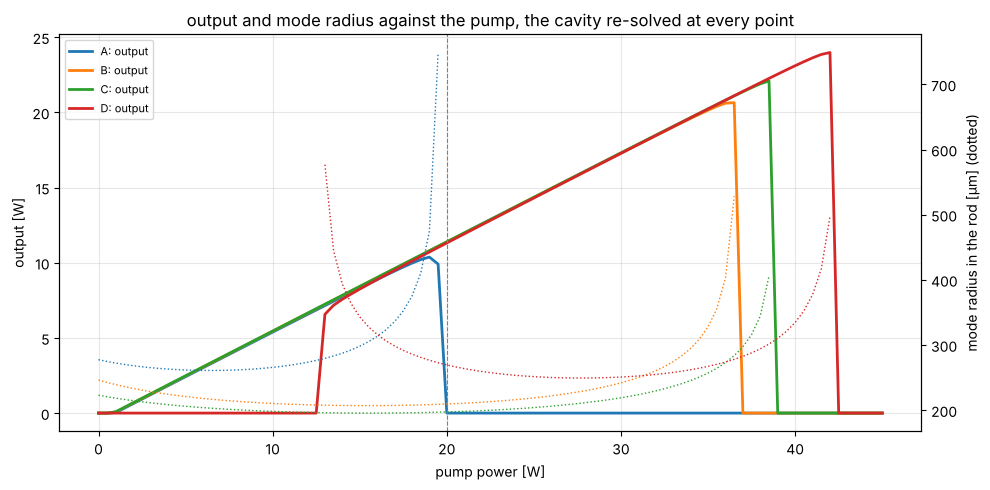

,lases from [W],output at 20 W [W],output at 30 W [W],mode at 20 W [µm],mode at 30 W [µm]
A,1.0,0.00,0.00,NaN,NaN
B,1.0,11.38,17.29,209.37,241.93
C,1.0,11.39,17.31,197.20,218.98
D,13.0,11.32,17.28,269.39,250.80


optical length [mm]                       2.281470e+02
FSR [MHz]                                 6.570170e+02
longitudinal modes under the gain line    1.826440e+02
round-trip survival                       8.880000e-01
photon lifetime [ns]                      1.285100e+01
finesse                                   5.304500e+01
cold-cavity linewidth [MHz]               1.238600e+01
Q                                         2.275135e+07
round-trip Gouy phase [rad]               4.182000e+00
transverse mode spacing [MHz]             4.372590e+02
Name: spectrum of D at 20 W, dtype: float64

In [10]:
pumps = np.linspace(0, 45, 91)
CURVES = {name: sv.power_curve(rev, W_PUMP, pumps) for name, rev in sv.REVISIONS.items()}
fig, ax = plt.subplots(figsize=(10, 5)); svd.power_view(CURVES, ax=ax, pump_design=PUMP_DESIGN); ax.set_title("output and mode radius against the pump, the cavity re-solved at every point")
plt.tight_layout(); plt.savefig(OUT / "power_curves.png", dpi=110); plt.show()
PC = pd.DataFrame({name: {"lases from [W]": float(c["pump_W"][np.argmax(c["output_W"] > 0)]) if (c["output_W"] > 0).any() else math.nan,
                          "output at 20 W [W]": float(np.interp(20, c["pump_W"], c["output_W"])), "output at 30 W [W]": float(np.interp(30, c["pump_W"], c["output_W"])),
                          "mode at 20 W [µm]": float(np.interp(20, c["pump_W"], c["w_rod"])) * 1e6, "mode at 30 W [µm]": float(np.interp(30, c["pump_W"], c["w_rod"])) * 1e6}
                   for name, c in CURVES.items()}).T
display(PC.round(2))
SPEC = OP["resonator"].spectrum()
display(pd.Series({"optical length [mm]": SPEC["optical_length"] * 1e3, "FSR [MHz]": SPEC["fsr"] / 1e6, "longitudinal modes under the gain line": sv.ND_LINEWIDTH_HZ / SPEC["fsr"],
                   "round-trip survival": SPEC["survival"], "photon lifetime [ns]": SPEC["photon_lifetime"] * 1e9, "finesse": SPEC["finesse"],
                   "cold-cavity linewidth [MHz]": SPEC["linewidth"] / 1e6, "Q": SPEC["Q"], "round-trip Gouy phase [rad]": SPEC.get("gouy_round_trip", math.nan),
                   "transverse mode spacing [MHz]": SPEC.get("transverse_mode_spacing", math.nan) / 1e6}, name=f"spectrum of {CHOSEN} at {PUMP_DESIGN:.0f} W").round(3))

### 6. The beam out and the delivery train

The mode on the output coupler leaves through its substrate — a concave inner face and a flat outer face, a weak negative
lens in fused silica whose cardinal points Hyperion gives — and is a Gaussian with a virtual waist behind the coupler. The
delivery train: a collimating lens one focal length from that waist, sized for a 1 mm collimated radius, a 150 mm stand-off,
a 50 mm focusing lens and the work spot: its radius, the depth of focus (2 z_R) and where it sits. All with M² = 1 — the
paraxial TEM₀₀; the beam-quality budget of the real laser is the FFT stage (S.6).

OC substrate: OC substrate, -334 mm focal length (negative: diverging)
beam out: 309 µm on the coupler, waist 215 µm at +137 mm from the outer face, half-angle divergence 1.58 mrad, Rayleigh range 136 mm


collimator f [mm]                       634.115
collimator from the OC [mm]             771.134
collimated radius [mm]                    1.013
focusing lens f [mm]                     50.000
work spot radius [µm]                    16.664
work spot from the lens [mm]             49.852
depth of focus 2 z_R [mm]                 1.640
intensity at the work spot [kW/cm²]    1297.353
Name: delivery, dtype: float64

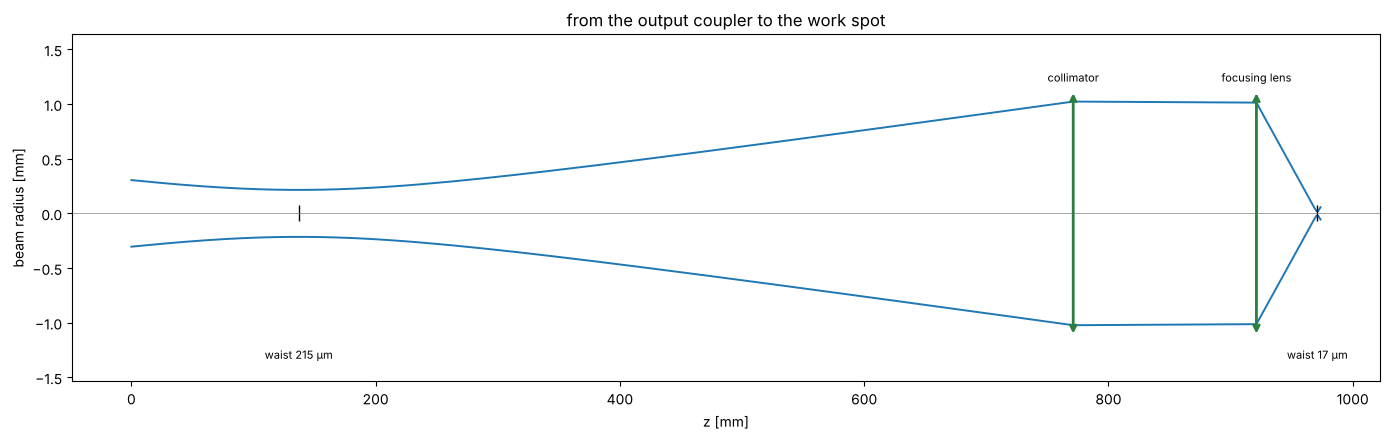

In [11]:
OB = sv.output_beam(OP["resonator"])
cp = OB["substrate"].cardinal_points(sv.LAM) if isinstance(OB["substrate"], hy.ThickLens) else {}
print(f"OC substrate: {OB['substrate'].name}, {cp.get('f', math.nan) * 1e3:.0f} mm focal length (negative: diverging)" if cp else "OC substrate: a flat plate")
print(f"beam out: {OB['w_oc'] * 1e6:.0f} µm on the coupler, waist {OB['w0'] * 1e6:.0f} µm at {OB['z0'] * 1e3:+.0f} mm from the outer face, "
      f"half-angle divergence {OB['divergence'] * 1e3:.2f} mrad, Rayleigh range {OB['rayleigh_range'] * 1e3:.0f} mm")
DL = sv.delivery_train(OB["beam"])
display(pd.Series({"collimator f [mm]": DL["f_collimator"] * 1e3, "collimator from the OC [mm]": DL["collimator_at"] * 1e3, "collimated radius [mm]": DL["w_collimated"] * 1e3,
                   "focusing lens f [mm]": 50.0, "work spot radius [µm]": DL["work_spot"] * 1e6, "work spot from the lens [mm]": DL["work_distance"] * 1e3,
                   "depth of focus 2 z_R [mm]": DL["depth_of_focus"] * 1e3, "intensity at the work spot [kW/cm²]": OP["output_W"] / (math.pi * DL["work_spot"] ** 2) / 1e7},
                  name="delivery").round(3))
fig, ax = plt.subplots(figsize=(14, 4.5)); svd.train_view(DL["trace"], ax=ax, title="from the output coupler to the work spot", scale_w=1e3, unit="mm")
plt.tight_layout(); plt.savefig(OUT / "delivery.png", dpi=110); plt.show()

### 7. The record

The chosen cavity (at the design pump and cold), the pump, the laser's numbers, the beam and the delivery train as Hyperion
objects in `designs/data/svarog_design.json` (`hyperion.load_design` reads them back); the tables of this notebook in
`designs/data/reports/46_svarog.json`. The exit gate checks both were written by this run and stamps them.

In [12]:
def _j(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    if hasattr(o, "to_dict"):
        return o.to_dict()
    if isinstance(o, float) and not math.isfinite(o):
        return None if math.isnan(o) else ("inf" if o > 0 else "-inf")
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return str(o)

REC = sv.design_record(REV, sv.PUMP, PUMP_DESIGN, W_PUMP)
ROD_REC = REC; hy.save_design(DATA / "svarog_design.json", REC, notes=f"Svarog revision {CHOSEN} at {PUMP_DESIGN:.0f} W pump (notebook 46)")
REPORT = {"meta": {"notebook": "46_svarog", "chosen": CHOSEN, "design_pump_W": PUMP_DESIGN, "wavelength": sv.LAM, "pump_wavelength": sv.LAM_P, "debug": DEBUG},
          "rod": sv.ROD.to_dict(), "pump": {**REC["pump"], "magnifications": MAG.to_dict(orient="index")},
          "coupler": {"table": COUP.to_dict(orient="index"), "optimum": OPT, "chosen_T": REV.T},
          "thermal_lens": TL.to_dict(orient="index"),
          "revisions": {k: {**v, **{"windows": WIN[k]["windows"]}} for k, v in sv.compare(sv.REVISIONS.values(), PUMP_DESIGN, W_PUMP).items()},
          "laser": REC["laser"], "power_curves": PC.to_dict(orient="index"), "spectrum": SPEC,
          "beam_out": REC["beam_out"].to_dict(), "delivery": {k: v for k, v in DL.items() if k not in ("train", "trace")}}
(DATA / "reports").mkdir(parents=True, exist_ok=True)
ROD_REPORT = REPORT
print("Part I recorded: svarog_design.json written; the report goes into reports/46_svarog.json at the end")

Part I recorded: svarog_design.json written; the report goes into reports/46_svarog.json at the end


### 8. Reading it

- **The pump decides the cavity.** A 200 µm fibre at NA 0.22 cannot be focused tighter than ≈ 280 µm *effective* radius
  in a 10 mm rod, and a larger spot is the better design: the thermal lens weakens with w_p², every window widens, and the
  threshold stays at a watt. Magnification 4 (a 400 µm spot) is the choice; a 100 µm fibre would move every number.
- **Magni's rule, not the mirrors, sets the TEM₀₀ mode** of a cavity that must lase from cold: w² = 2λ/(π ΔD). To fill the
  pump the window must be narrow in dioptres — a zone-II cavity that the lens itself opens (D). Its price: nothing below 13 W,
  and a mode that changes with the pump; its reward: a mode two thirds of the pump spot (42 % of the pump inside it) at 20 W,
  against a quarter for the cavities that lase from cold.
- **The output is insensitive** to all of it (11–12 W at 20 W for every revision that lases): slope and threshold are the
  medium's and the coupler's. What the cavity decides is *which* modes carry that power.
- **The numbers are paraxial, closed-form, steady.** The thermal lens is ±30 % until measured (η_heat, the stress share, the
  real pump profile); the real window moves with it, which is why D's is wide. Ray tracing (S.1), the rod's thermal analysis
  (S.2), the mounts and their stiffness (S.3, S.4) and the physical-optics beam quality (S.6) are the next notebooks.

# Part II — the fibre laser

**Svarog-fiber** is the fibre twin of Svarog's rod (Part I): a 1070 nm continuous-wave laser whose cavity *is* the
gain medium — a 10/125 µm Yb-doped double-clad fibre between two fibre Bragg gratings, pumped at 976 nm by fibre-coupled
diodes through a combiner — followed by one amplifier stage in a 20/125 µm fibre. Everything is computed with Hyperion's
`fibre` module ([docs/hyperion.md](../docs/hyperion.md)): the fibres' modes, cutoffs and bend loss; the pump and the two
signal waves along the fibre from the rate equations, shot to the gratings' reflectivities; the amplifier's single pass; the
Raman threshold and the core's temperature. The device as numbers is `designs/svarog_fiber.py` (`import svarog_fiber as sf`);
the drawings `designs/svarog_fiber_drawings.py`. Part I's record (`designs/data/reports/46_svarog.json`) is read for the
comparison with the rod at the same 20 W; when it is missing the comparison says so and shows the fibre alone.

The record goes to `designs/data/svarog_fiber_design.json` (the oscillator, the amplifier, the beam and the delivery train as
Hyperion objects) and `designs/data/reports/47_svarog_fiber.json`. Not here: ASE and the noise of a weak-seed preamplifier, the
higher-mode stripping of the few-mode amplifier fibre, pulses — `svarog_todo.md` S.5.

In [13]:
OUT = Path("output/47_svarog_fiber"); OUT.mkdir(parents=True, exist_ok=True)
PUMP_AMP = 50.0                                      # W launched into the amplifier (six 9 W diodes through the combiner)
R46_PATH = DATA / "reports" / "46_svarog.json"
R46 = ROD_REPORT

### 1. The fibres, their modes, the pumps

Two fibres: the oscillator's **10/125** (core Ø10 µm, NA 0.075 — single-mode at 1070 nm, V = 2.20) and the amplifier's
**20/125** (NA 0.06, V = 3.5: a few-mode fibre whose LP₁₁ a coil must strip). Marcuse's fit gives the LP₀₁ radius; the
overlap factors Γ_s (the mode inside the core) and Γ_p = (a/b)² (the cladding pump crossing the core) are what the rate
equations see. The doping is not a number the model picks: the datasheet's cladding absorption at 976 nm (1.7 and 5 dB/m)
sets the ion density. The pumps are 9 W diodes on 105/125 µm, NA 0.22 pigtails through a (6+1)×1 combiner — the étendue
check says how many fit the 125 µm, NA 0.46 cladding.

In [14]:
rows = {}
for f in (sf.FIBRE_OSC, sf.FIBRE_AMP):
    act = sf.active(f, 1.0)
    rows[f.name] = {"core Ø [µm]": 2 * f.core_radius * 1e6, "NA": f.NA, "clad Ø [µm]": 2 * f.clad_radius * 1e6, "V at 1070": f.V(sf.LAM), "V at 976": f.V(sf.LAM_P),
                    "single-mode at 1070": f.single_mode(sf.LAM), "cutoff [nm]": f.cutoff_wavelength * 1e9, "MFD at 1070 [µm]": 2 * f.mode_radius(sf.LAM) * 1e6,
                    "Γ_s": f.overlap_core(sf.LAM), "Γ_p": f.overlap_clad, "absorption at 976 [dB/m]": act.absorption_db_per_m(sf.LAM_P),
                    "absorption at 915 [dB/m]": act.absorption_db_per_m(915e-9), "Yb ions [1e25/m³]": act.dopant.N / 1e25,
                    "far-field half-angle [mrad]": f.beam(sf.LAM).divergence * 1e3}
FIB = pd.DataFrame(rows).T; display(FIB.round(3))
for pump, f in ((sf.PUMP_OSC, sf.FIBRE_OSC), (sf.PUMP_AMP, sf.FIBRE_AMP)):
    fit = pump.fits_the_cladding(f)
    print(f"{f.name}: {pump.n_diodes} × {pump.diode_W:g} W diodes → {pump.power_max:.1f} W launched at most; étendue: {fit['ports_that_fit']} ports fit, {fit['used']} used — {'ok' if fit['fits'] else 'does not fit'}")
sa, se = fb.YB_SILICA.cross_sections(sf.LAM_P); sas, ses = fb.YB_SILICA.cross_sections(sf.LAM)
print(f"Yb:silica — at 976 nm σ_a {sa:.2e}, σ_e {se:.2e} m²; at 1070 nm σ_a {sas:.1e}, σ_e {ses:.1e} m²; τ {fb.YB_SILICA.tau * 1e3:.2f} ms; quantum limit λ_p/λ_s = {sf.QUANTUM_LIMIT:.3f}")

,core Ø [µm],NA,clad Ø [µm],V at 1070,V at 976,single-mode at 1070,cutoff [nm],MFD at 1070 [µm],Γ_s,Γ_p,absorption at 976 [dB/m],absorption at 915 [dB/m],Yb ions [1e25/m³],far-field half-angle [mrad]
10/125 Yb double-clad,10.0,0.075,125.0,2.202051,2.414134,True,979.777535,11.707078,0.767592,0.0064,1.7,0.51,2.446497,58.185585
20/125 Yb double-clad,20.0,0.06,125.0,3.523281,3.862614,False,1567.644056,17.926264,0.917048,0.0256,5.0,1.5,1.798895,37.99917


10/125 Yb double-clad: 3 × 9 W diodes → 25.6 W launched at most; étendue: 6 ports fit, 3 used — ok
20/125 Yb double-clad: 6 × 9 W diodes → 51.3 W launched at most; étendue: 6 ports fit, 6 used — ok
Yb:silica — at 976 nm σ_a 2.50e-24, σ_e 2.50e-24 m²; at 1070 nm σ_a 8.0e-27, σ_e 2.8e-25 m²; τ 0.85 ms; quantum limit λ_p/λ_s = 0.912


### 2. The oscillator

The active fibre between the gratings (HR 99 % with 0.3 dB of splice and grating loss per pass folded in; OC 10 %), pumped
from the HR end. For each length Hyperion integrates the pump and both signal waves along z and shoots on the circulating
power until the backward wave at the coupler is R_oc times the forward one; the output is what the coupler lets through.
The length: the output rises while the fibre absorbs more pump and flattens once little is left — the rule is the shortest
fibre within 3 % of the best. The coupler: at this gain the output is flat from 4 % to 20 % reflectivity; 10 % keeps the
inversion and the circulating power moderate. Then the power evolution along the chosen fibre, the threshold (the
small-signal round trip reaching 1), the slope and the power curve up to the three diodes' 25.6 W.

length: the best 13 m gives 16.32 W; chosen 9 m (shortest within 3% of the best): 15.98 W, 0.84 W of pump unabsorbed  [4 s]


,output_W,threshold_W,circulating_at_OC_W,gain_db_one_way,inversion_max
R_oc,,,,,
0.04,16.276,0.274,16.954,7.312,0.159
0.07,16.126,0.249,17.340,6.096,0.132
0.10,15.982,0.232,17.758,5.322,0.117
0.15,15.744,0.214,18.523,4.441,0.101
0.20,15.502,0.201,19.378,3.817,0.090
0.30,14.981,0.183,21.402,2.936,0.075


oscillator at 20 W: output 15.98 W (80% of the launched pump, 91% of the quantum limit on the absorbed), threshold 0.23 W, slope 0.808; heat 2.14 W, peak 0.60 W/m; inversion 3.0%–11.7%


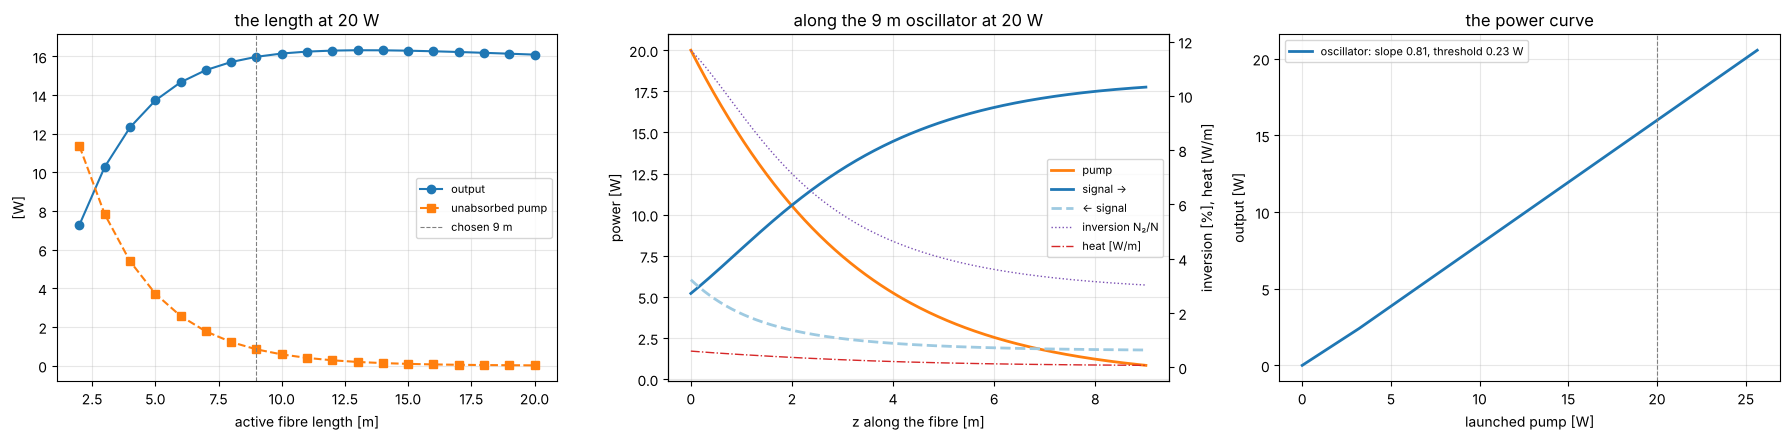

In [15]:
t0 = time.time()
LC = sf.length_choice(PUMP_OSC, n=sf.N_SWEEP)
LEN = LC["chosen_length"]
print(f"length: the best {LC['best_length']:g} m gives {LC['best_output_W']:.2f} W; chosen {LEN:g} m ({LC['rule']}): {LC['chosen_output_W']:.2f} W, {LC['chosen_unabsorbed_W']:.2f} W of pump unabsorbed  [{time.time() - t0:.0f} s]")
CC = pd.DataFrame(sf.coupler_choice(LEN, PUMP_OSC, n=sf.N_SWEEP)).T; CC.index.name = "R_oc"; display(CC.round(3))
OSC = sf.oscillator(LEN)
S_OSC = OSC.solve(PUMP_OSC, n=sf.N_FINE)
TH = OSC.threshold(n=sf.N_SWEEP)
PC = OSC.power_curve(np.linspace(0, sf.PUMP_OSC.power_max, 9), n=sf.N_SWEEP)
print(f"oscillator at {PUMP_OSC:.0f} W: output {S_OSC.output_W:.2f} W ({S_OSC.efficiency:.0%} of the launched pump, {S_OSC.output_W / S_OSC.absorbed_W / sf.QUANTUM_LIMIT:.0%} of the quantum limit on the absorbed), "
      f"threshold {TH:.2f} W, slope {PC['slope']:.3f}; heat {S_OSC.heat_W:.2f} W, peak {S_OSC.peak_heat_per_m:.2f} W/m; inversion {S_OSC.inversion.min():.1%}–{S_OSC.inversion.max():.1%}")
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
sfd.length_view(LC, ax=axs[0], title=f"the length at {PUMP_OSC:.0f} W")
sfd.evolution_view(S_OSC, ax=axs[1], title=f"along the {LEN:g} m oscillator at {PUMP_OSC:.0f} W")
sfd.power_view({"oscillator": PC}, ax=axs[2], pump_design=PUMP_OSC); axs[2].set_title("the power curve")
plt.tight_layout(); plt.savefig(OUT / "oscillator.png", dpi=110); plt.show()

### 3. The amplifier stage

The oscillator's output seeds a 20/125 fibre counter-pumped with 50 W (six diodes); the counter-pump is shot to its launched
power at the output end. The length by the same rule; co- and counter-pumping compared: the same energy, a different
inversion profile — the counter-pumped fibre has its strongest inversion where the signal is strongest, and its heat
there; the co-pumped one has it at the weak-signal end, where the inversion is highest (the photodarkening end).

amplifier length: the best 6.5 m; chosen 3.5 m (shortest within 3% of the best): 58.9 W  [4 s]


,counter-pumped,co-pumped
output_W,58.880,58.739
pump_W,50.000,50.000
absorbed_W,47.916,47.919
unabsorbed_W,2.084,2.081
gain_db,5.663,5.653
efficiency,1.178,1.175
heat_W,4.557,4.701
peak_heat_per_m,3.728,2.395
inversion_max,0.156,0.300
inversion_min,0.053,0.035


the stage: 16.0 W in, 58.9 W out (5.7 dB), 2.1 W of pump left; whole device: 70 W of pump → 58.9 W, 84%


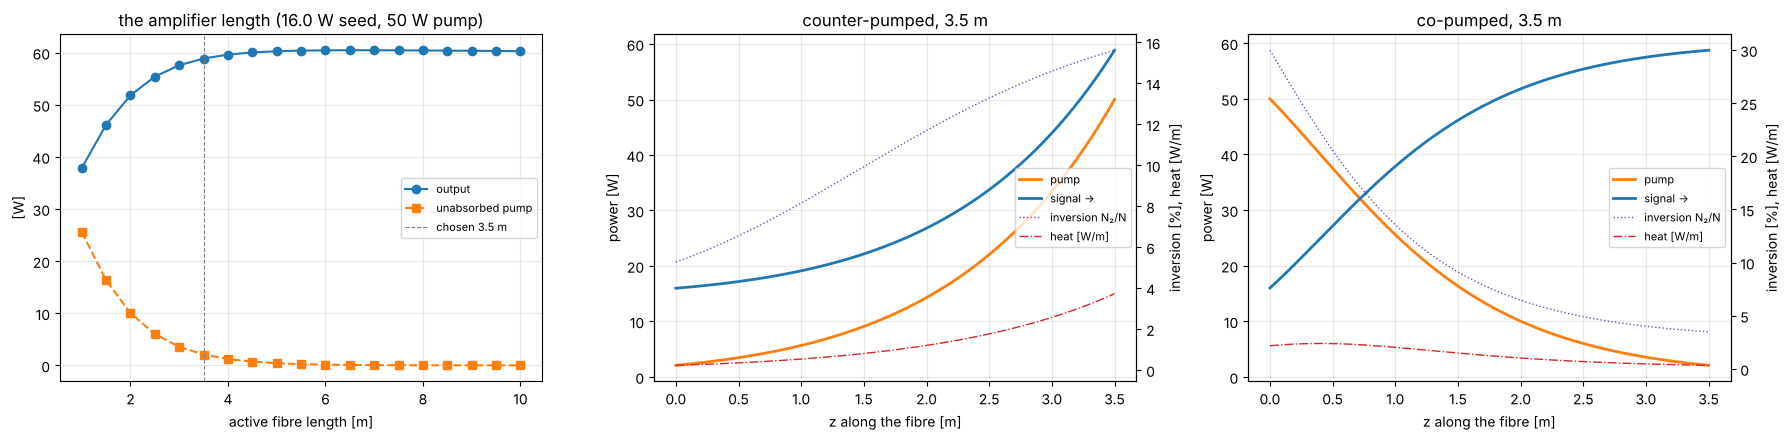

In [16]:
t0 = time.time()
AC = sf.amplifier_length_choice(S_OSC.output_W, PUMP_AMP, n=sf.N_SWEEP)
ALEN = AC["chosen_length"]
print(f"amplifier length: the best {AC['best_length']:g} m; chosen {ALEN:g} m ({AC['rule']}): {AC['chosen_output_W']:.1f} W  [{time.time() - t0:.0f} s]")
AMP = sf.amplifier(ALEN, "counter"); S_AMP = AMP.solve(S_OSC.output_W, PUMP_AMP, n=sf.N_FINE)
S_CO = sf.amplifier(ALEN, "co").solve(S_OSC.output_W, PUMP_AMP, n=sf.N_FINE)
AT = pd.DataFrame({"counter-pumped": S_AMP.to_dict(), "co-pumped": S_CO.to_dict()}).drop(index=["note"]); display(AT.astype(float).round(3))
print(f"the stage: {S_OSC.output_W:.1f} W in, {S_AMP.output_W:.1f} W out ({S_AMP.gain_db:.1f} dB), {S_AMP.unabsorbed_W:.1f} W of pump left; "
      f"whole device: {PUMP_OSC + PUMP_AMP:.0f} W of pump → {S_AMP.output_W:.1f} W, {S_AMP.output_W / (PUMP_OSC + PUMP_AMP):.0%}")
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
sfd.length_view(AC, ax=axs[0], title=f"the amplifier length ({S_OSC.output_W:.1f} W seed, {PUMP_AMP:.0f} W pump)")
sfd.evolution_view(S_AMP, ax=axs[1], title=f"counter-pumped, {ALEN:g} m")
sfd.evolution_view(S_CO, ax=axs[2], title=f"co-pumped, {ALEN:g} m")
plt.tight_layout(); plt.savefig(OUT / "amplifier.png", dpi=110); plt.show()

### 4. The coil and the limits

Marcuse's bend loss of LP₀₁ against the coil radius for both fibres, and the smallest radius at which the whole length
loses no more than 0.05 dB — the spool's size. (The 20/125's LP₁₁ is bent out at a radius the fundamental survives; that
budget is the few-mode stripping of S.5.4's open item, not this curve.) The limits: stimulated Raman scattering against
the signal in the amplifier fibre (Smith's 16 A_eff/g_R L_eff — far away for CW watts, the first wall for pulses), and the
core's temperature at the hottest metre for four coolings: still air, a plate, a cooled spool, a water-cooled groove.

coil radius for ≤ 0.05 dB over the length: {'oscillator': '46 mm', 'amplifier': '52 mm'}
SRS threshold: oscillator fibre 1934 W (109× the circulating power), amplifier fibre 11584 W (197× the output); Stokes line 1123 nm


,oscillator (0.60 W/m peak),amplifier (3.73 W/m peak)
still air,76.8,477.8
on a plate,15.8,98.0
on a cooled spool,2.1,12.6
in a water-cooled groove,0.9,5.4


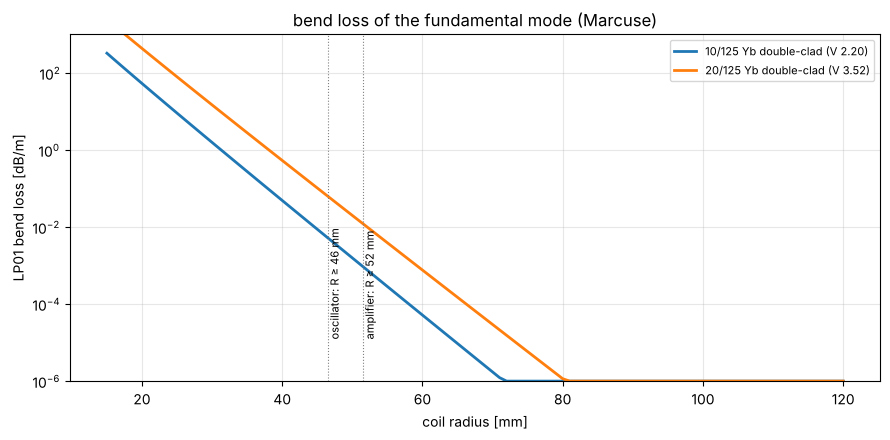

In [17]:
COILS = {sf.FIBRE_OSC.name: sf.coil(sf.FIBRE_OSC), sf.FIBRE_AMP.name: sf.coil(sf.FIBRE_AMP)}
RADII = {"oscillator": sf.coil_radius_for(sf.FIBRE_OSC, LEN), "amplifier": sf.coil_radius_for(sf.FIBRE_AMP, ALEN)}
print("coil radius for ≤ 0.05 dB over the length:", {k: f"{v * 1e3:.0f} mm" for k, v in RADII.items()})
LIM_OSC = sf.limits(sf.FIBRE_OSC, LEN, S_OSC, S_OSC.Ps_fwd[-1])
LIM_AMP = sf.limits(sf.FIBRE_AMP, ALEN, S_AMP, S_AMP.output_W)
print(f"SRS threshold: oscillator fibre {LIM_OSC['srs']['P_threshold_W']:.0f} W ({LIM_OSC['srs_margin']:.0f}× the circulating power), amplifier fibre "
      f"{LIM_AMP['srs']['P_threshold_W']:.0f} W ({LIM_AMP['srs_margin']:.0f}× the output); Stokes line {LIM_AMP['srs']['stokes_wavelength'] * 1e9:.0f} nm")
TEMP = pd.DataFrame({f"{name} ({lim['peak_heat_per_m']:.2f} W/m peak)": {c: t["dT_core_to_sink"] for c, t in lim["temperatures"].items()}
                     for name, lim in (("oscillator", LIM_OSC), ("amplifier", LIM_AMP))}); display(TEMP.round(1))
fig, ax = plt.subplots(figsize=(9, 4.5)); sfd.coil_view(COILS, ax=ax, budgets=RADII)
plt.tight_layout(); plt.savefig(OUT / "coil.png", dpi=110); plt.show()

### 5. The beam out and the delivery train

The LP₀₁ leaving the amplifier's angled cleave or end cap: a 9 µm waist diverging at 2.2°, M² 1.05 — no thermal lens, no
cavity alignment, the fibre's geometry alone. Svarog's delivery train sized for the same 1 mm collimated radius, the same
stand-off and 50 mm focusing lens, so the work spots compare: the collimator is a 25 mm lens instead of the rod's 634 mm one.

waist at the fibre end [µm]               8.963
half-angle divergence [mrad]             39.899
M²                                        1.050
collimator f [mm]                        25.205
collimated radius [mm]                    1.007
focusing lens f [mm]                     50.000
work spot radius [µm]                    17.775
depth of focus 2 z_R [mm]                 1.777
intensity at the work spot [kW/cm²]    5932.288
Name: delivery, dtype: float64

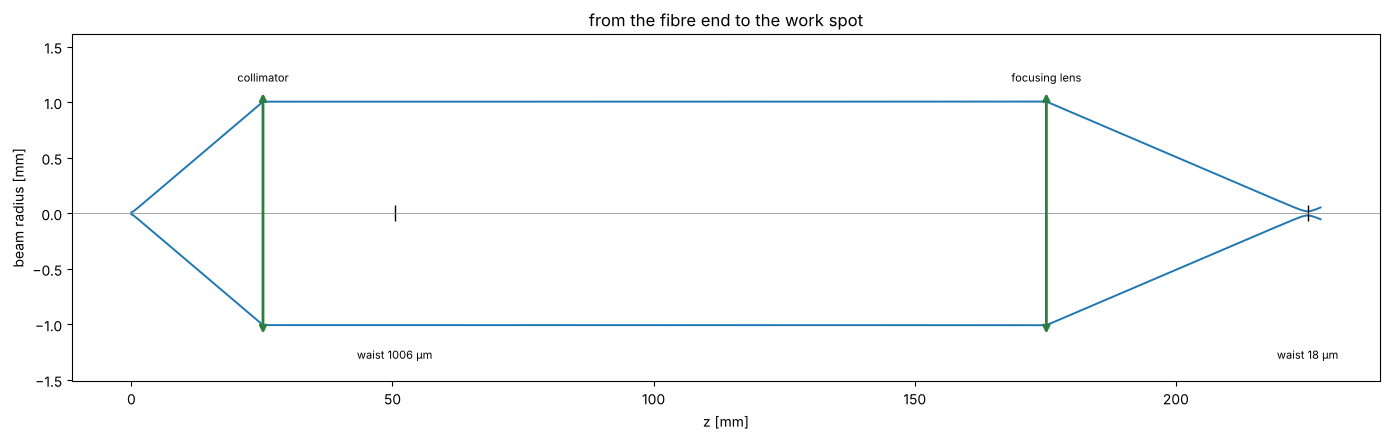

In [18]:
BEAM = sf.beam_out(sf.FIBRE_AMP)
DL = sf.delivery(BEAM)
display(pd.Series({"waist at the fibre end [µm]": BEAM.w0 * 1e6, "half-angle divergence [mrad]": BEAM.divergence * 1e3, "M²": BEAM.m2,
                   "collimator f [mm]": DL["f_collimator"] * 1e3, "collimated radius [mm]": DL["w_collimated"] * 1e3, "focusing lens f [mm]": 50.0,
                   "work spot radius [µm]": DL["work_spot"] * 1e6, "depth of focus 2 z_R [mm]": DL["depth_of_focus"] * 1e3,
                   "intensity at the work spot [kW/cm²]": S_AMP.output_W / (math.pi * DL["work_spot"] ** 2) / 1e7}, name="delivery").round(3))
fig, ax = plt.subplots(figsize=(14, 4.5)); svd.train_view(DL["trace"], ax=ax, title="from the fibre end to the work spot", scale_w=1e3, unit="mm")
plt.tight_layout(); plt.savefig(OUT / "delivery.png", dpi=110); plt.show()

### 6. Against the rod

The oscillator at the rod's work point (20 W launched) against Part I's record: what each gives, what it costs in
heat, what its beam is, and what each is sensitive to.

In [19]:
CMP = sf.against_the_rod(R46, S_OSC, TH, PC["slope"], DL, BEAM, PUMP_OSC)
VS = pd.DataFrame(CMP["rows"], index=["Svarog-fiber (oscillator)", "Svarog (rod, revision D)"]).T; display(VS.round(3))
if not CMP["have_rod"]:
    print("the rod's column is empty: Part I's report was not found")
for k, v in CMP["sensitivities"].items():
    print(f"{k}: sensitive to {v}")

,Svarog-fiber (oscillator),"Svarog (rod, revision D)"
pump at the work point [W],20.000,20.000
output [W],15.982,11.317
optical efficiency,0.799,0.566
threshold [W],0.232,0.939
slope,0.808,0.594
heat in the gain medium [W],2.141,5.890
beam waist [µm],8.963,214.763
beam divergence [mrad],39.899,1.577
M²,1.050,1.000
work spot radius [µm],17.775,16.664


fibre: sensitive to the gratings' wavelengths and temperature, splice losses, the pump diodes' wavelength against the 976 nm peak, bend loss, SRS at high power
rod: sensitive to the thermal lens (η_heat, the pump spot), the cavity's alignment, the mode–pump overlap, the rod's fracture limit


### 7. The record

The oscillator and the amplifier (Hyperion objects), the pumps, the beam and the delivery train in
`designs/data/svarog_fiber_design.json`; this notebook's tables in `designs/data/reports/47_svarog_fiber.json`. The exit gate
checks both were written by this run and stamps them.

In [20]:
def _j(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    if hasattr(o, "to_dict"):
        return o.to_dict()
    if isinstance(o, float) and not math.isfinite(o):
        return None if math.isnan(o) else ("inf" if o > 0 else "-inf")
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return str(o)

REC = sf.design_record(LEN, OSC.R_oc, PUMP_OSC, ALEN, PUMP_AMP, BEAM, DL)
FIBRE_REC = REC; hy.save_design(DATA / "svarog_fiber_design.json", REC, notes=f"Svarog-fiber: {LEN:g} m oscillator at {PUMP_OSC:.0f} W, {ALEN:g} m amplifier at {PUMP_AMP:.0f} W (notebook 47)")
REPORT = {"meta": {"notebook": "47_svarog_fiber", "pump_osc_W": PUMP_OSC, "pump_amp_W": PUMP_AMP, "wavelength": sf.LAM, "pump_wavelength": sf.LAM_P, "debug": DEBUG,
                   "rod_report": str(R46_PATH) if R46 else None},
          "fibres": FIB.to_dict(orient="index"),
          "oscillator": {"length": LEN, "R_hr_effective": OSC.R_hr, "R_oc": OSC.R_oc, "length_choice": {k: v for k, v in LC.items()}, "coupler": CC.to_dict(orient="index"),
                         "threshold_W": TH, "slope": PC["slope"], "power_curve": {k: v for k, v in PC.items()}, **S_OSC.to_dict()},
          "amplifier": {"length": ALEN, "seed_W": S_OSC.output_W, "length_choice": {k: v for k, v in AC.items()}, "counter": S_AMP.to_dict(), "co": S_CO.to_dict()},
          "coil": {"radius_for_0.05dB": RADII, "V": {k: c["V"] for k, c in COILS.items()}},
          "limits": {"oscillator": {"srs": LIM_OSC["srs"], "srs_margin": LIM_OSC["srs_margin"], "temperatures": LIM_OSC["temperatures"]},
                     "amplifier": {"srs": LIM_AMP["srs"], "srs_margin": LIM_AMP["srs_margin"], "temperatures": LIM_AMP["temperatures"]}},
          "beam_out": BEAM.to_dict(), "delivery": {k: v for k, v in DL.items() if k not in ("train", "trace")},
          "against_the_rod": {"rows": {k: list(v) for k, v in CMP["rows"].items()}, "have_rod": CMP["have_rod"], "sensitivities": CMP["sensitivities"]}}
(DATA / "reports").mkdir(parents=True, exist_ok=True)
FIBRE_REPORT = REPORT
print("Part II recorded: svarog_fiber_design.json written")

Part II recorded: svarog_fiber_design.json written


### 8. Reading it

- **The fibre has no thermal lens and no alignment.** Where the rod's design was the fight between the pump's lens and the
  cavity's window, the fibre's is a length and two gratings: the output follows the quantum limit times the coupling, the
  threshold is a fifth of a watt, and the beam is the fibre's mode whatever the pump does. Its own sensitivities are the
  gratings' wavelength (temperature-tuned), the splices, the diode wavelength against the 976 nm absorption peak, and the coil.
- **The length is a cost-and-margin choice, not a physics one**, once the fibre absorbs ~90 % of the pump: the curve is flat,
  and the shorter fibre has the higher SRS threshold and the easier coil; the unabsorbed pump must be stripped at the
  splice (a cladding-mode stripper, S.3 for the fibre).
- **Heat is spread**, a few watts per metre at the pump end — harmless on a cooled spool, not in still air. The amplifier's
  pump end is the hot metre and the photodarkening end; counter-pumping puts the strongest inversion under the strongest signal.
- **At the same 20 W, the fibre gives half again the rod's output** and a diffraction-limited beam into a 25 mm collimator; the
  rod gives a free-space cavity to put a Q-switch or a doubling crystal in, and no fibre to damage at high peak power. The
  limits that are not here — ASE of a weak seed, the few-mode coil's stripping budget, SRS and self-focusing of pulses — are
  the fibre's next items in `svarog_todo.md`.

# Part III — the industrial lasers: 1 kW and 2 kW, topic by topic

Two devices on one code path (`si.Device`): the **1 kW** — one 30/250 Yb stage seeded by Part II's amplifier, six 220 W
976 nm modules through a (6+1)×1 combiner, a 50 µm process fibre and a 100/200 welding head — and the **2 kW**, which is
*two of those modules beam-combined* through a (2+1)×1 signal combiner into a 100 µm fibre (route A, the product: each
module runs as designed, the price is beam quality). The alternative, one stage pumped by 400 W modules (route B), is
shown where it differs — the stage and its heat. Every topic below runs the devices one after the other and puts them in
one table.

In [21]:
SEED = S_AMP.output_W                                 # Part II's amplifier seeds the power stages
DEV = si.devices(SEED)
D1, D2, D2B = DEV["1kW"], DEV["2kW"], DEV["2kW-B"]
display(pd.DataFrame({d.name: {"target at the stage [W]": d.target_W, "pump modules": f"{d.pump.n_modules} × {d.pump.module_W:g} W", "launched max [W]": d.pump.launched_max,
                               "seed [W]": d.seed_W, "process fibre": d.delivery.name, "head": d.head.name, "combined": d.combined is not None, "note": d.note} for d in (D1, D2, D2B)}).T)

,target at the stage [W],pump modules,launched max [W],seed [W],process fibre,head,combined,note
1 kW,1000.0,6 × 220 W,1254.0,58.880367,"50/125 process fibre, 20 m",welding head 100/200,False,"one 30/250 stage on six 220 W modules, a 50 µm process fibre"
2 kW (A: two modules combined),2000.0,6 × 220 W,1254.0,58.880367,"100/125 process fibre, 20 m",welding head 100/200,True,"two 1 kW modules through a (2+1)×1 signal combiner into a 100 µm process fibre: M² 18,..."
"2 kW (B: one stage, 400 W modules)",2000.0,6 × 400 W,2280.0,58.880367,"50/125 process fibre, 20 m",welding head 100/200,False,"one 30/250 stage on six 400 W modules; 2 kW through one fibre, 220 W of heat on one spool"


### 1. The power stage

For each device: the fibre's étendue check, the length by the 3 % rule at the modules' maximum, the pump that puts the
target out, the power evolution along the fibre. The 2 kW-A is two 1 kW stages, so its stage *is* the 1 kW's; 2 kW-B is
the same fibre pumped twice as hard.

stages solved in 33 s


,length [m],pump launched [W],stage out [W],gain [dB],unabsorbed pump [W],efficiency on the pump,heat in the fibre [W],peak heat [W/m],inversion max,SRS margin,coil radius [mm],delivered to the head [W],per module [W],after the combiner [W]
1 kW,10.0,1077.03,1000.0,12.30,28.56,0.93,105.21,37.57,0.12,7.02,49.5,933.25,NaN,NaN
2 kW (A: two modules combined),10.0,1077.03,1000.0,12.30,28.56,0.93,105.21,37.57,0.12,7.02,49.5,1810.51,1000.0,1940.0
"2 kW (B: one stage, 400 W modules)",10.0,2230.06,2000.0,15.31,70.81,0.90,215.61,77.13,0.13,3.51,49.5,1866.51,NaN,NaN


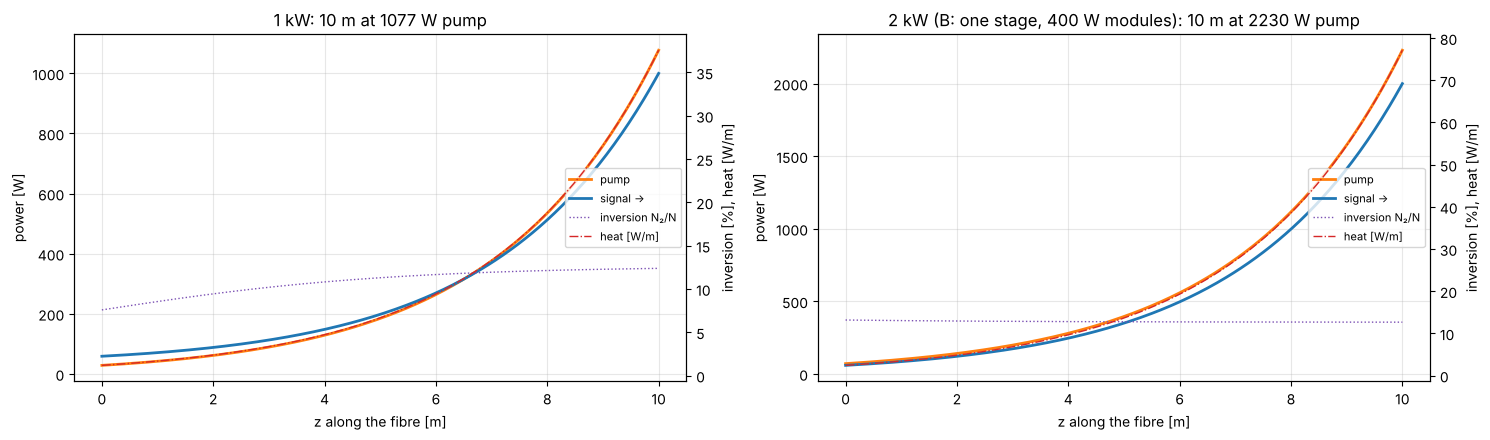

In [22]:
t0 = time.time()
ST = {k: d.stage() for k, d in DEV.items()}
print(f"stages solved in {time.time() - t0:.0f} s")
rows = {}
for k, d in DEV.items():
    st = ST[k]; sol = st["sol"]
    rows[d.name] = {"length [m]": st["length"], "pump launched [W]": st["pump_W"], "stage out [W]": sol.output_W, "gain [dB]": sol.gain_db, "unabsorbed pump [W]": sol.unabsorbed_W,
                    "efficiency on the pump": sol.efficiency, "heat in the fibre [W]": sol.heat_W, "peak heat [W/m]": sol.peak_heat_per_m, "inversion max": float(sol.inversion.max()),
                    "SRS margin": st["limits"]["srs_margin"], "coil radius [mm]": st["coil_radius"] * 1e3,
                    "delivered to the head [W]": st["delivered_W"], **({"per module [W]": st["per_module_W"], "after the combiner [W]": st["at_combiner_W"]} if "combined" in st else {})}
STAGE = pd.DataFrame(rows).T; display(STAGE.round(2))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, k in zip(axs, ("1kW", "2kW-B")):
    sfd.evolution_view(ST[k]["sol"], ax=ax, title=f"{DEV[k].name}: {ST[k]['length']:g} m at {ST[k]['pump_W']:.0f} W pump")
plt.tight_layout(); plt.savefig(OUT / "stages.png", dpi=110); plt.show()

### 2. The heat budget

Where the watts go in each device: the active fibre's heat and the core's rise per cooling, the cladding-mode stripper,
the process fibre, the head's lenses. Conduction bookkeeping on catalogue parts — no FEA; the cooling is the design.

In [23]:
rows = {}
for k, d in DEV.items():
    b = ST[k]["budget"]
    rows[d.name] = {"active fibre heat [W]": b["active_fibre_heat_W"], "peak [W/m]": b["active_fibre_peak_W_per_m"], **{f"core rise, {c} [K]": v for c, v in b["core_dT_per_cooling"].items()},
                    "into the stripper [W]": b["stripper_W"], "process fibre loss [W]": b["delivery_loss_W"], "absorbed per lens [W]": b["lens_absorbed_W_each"], "lens centre rise [K]": b["lens_centre_dT"]}
    if "combined" in ST[k]:
        rows[d.name]["note"] = "per module; two modules, two spools"
BUDGET = pd.DataFrame(rows).T; display(BUDGET.round(2))

,active fibre heat [W],peak [W/m],"core rise, water-cooled spool (h 2000) [K]","core rise, cooled plate (h 500) [K]","core rise, still air (h 10) [K]",into the stripper [W],process fibre loss [W],absorbed per lens [W],lens centre rise [K],note
1 kW,105.214562,37.567112,40.350779,85.193216,3014.899112,51.321359,66.745699,1.866509,55.702364,NaN
2 kW (A: two modules combined),105.214562,37.567112,40.350779,85.193216,3014.899112,51.321359,66.745699,1.866509,55.702364,"per module; two modules, two spools"
"2 kW (B: one stage, 400 W modules)",215.606609,77.13391,82.849416,174.92124,6190.280361,116.334762,133.491398,3.733017,111.404727,NaN


### 3. The delivery and the head

The process fibre's beam parameter product is the invariant: 50 µm/0.12 is 3 mm·mrad (M² 9), the 2 kW's 100 µm fibre
6 mm·mrad (M² 18); through the same 100/200 head a 100 µm and a 200 µm spot, the same 60 mrad cone, 12 and 6 MW/cm².
The collimated beam's 12 mm radius is the number the guard needs.

In [24]:
HN = {k: DEV[k].head_numbers(ST[k]["delivered_W"]) for k in ("1kW", "2kW")}
display(pd.DataFrame({DEV[k].name: {"delivered [W]": ST[k]["delivered_W"], "BPP [mm·mrad]": h["bpp_mm_mrad"], "M²": h["m2"], "collimated radius [mm]": h["collimated_radius"] * 1e3,
                                    "spot radius [µm]": h["spot_radius"] * 1e6, "cone half-angle [mrad]": h["cone_half_angle"] * 1e3, "Rayleigh length [mm]": h["rayleigh_length"] * 1e3,
                                    "irradiance at the spot [MW/cm²]": h["mean_irradiance_W_per_cm2"] / 1e6, "SRS threshold, process fibre [kW]": h["srs_delivery"]["P_threshold_W"] / 1e3}
                      for k, h in HN.items()}).T.round(3))

,delivered [W],BPP [mm·mrad],M²,collimated radius [mm],spot radius [µm],cone half-angle [mrad],Rayleigh length [mm],irradiance at the spot [MW/cm²],"SRS threshold, process fibre [kW]"
1 kW,933.254,3.0,8.808,12.0,50.0,60.0,0.833,11.883,7.256
2 kW (A: two modules combined),1810.513,6.0,17.616,12.0,100.0,60.0,1.667,5.763,27.813


### 4. The welds

Mild steel and aluminium under each device's spot: the keyhole threshold (the surface boiling under a steady Gaussian
spot — ~1 MW/cm² for steel, ten times that for aluminium, which is why aluminium needs the kilowatt), the penetration
against speed from the energy balance with Swift-Hook & Gick's melting efficiency, and the process window per thickness.
Depth follows power over width: the 2 kW's 200 µm spot lands between the 1 kW's 100 µm and the 2 kW-B's 100 µm.

1 kW: keyhole thresholds {'mild steel': '37 W', 'aluminium': '512 W'}
2 kW (A: two modules combined): keyhole thresholds {'mild steel': '75 W', 'aluminium': '1023 W'}
2 kW (B: one stage, 400 W modules): keyhole thresholds {'mild steel': '37 W', 'aluminium': '512 W'}


0.3 m/min  0.5 m/min  0.75 m/min  1 m/min  1.5 m/min  2 m/min  3 m/min  4 m/min  6 m/min  8 m/min  10 m/min
1 kW                               mild steel       4.46       3.38        2.70     2.29       1.82     1.53     1.20     1.01     0.78     0.65      0.56
                                   aluminium        3.79       2.91        2.36     2.03       1.64     1.41     1.13     0.97     0.77     0.66      0.58
2 kW (A: two modules combined)     mild steel       5.92       4.45        3.52     2.98       2.34     1.96     1.52     1.26     0.96     0.79      0.68
                                   aluminium        5.14       3.94        3.18     2.73       2.19     1.88     1.50     1.28     1.01     0.86      0.75
2 kW (B: one stage, 400 W modules) mild steel       8.91       6.75        5.39     4.58       3.63     3.07     2.41     2.02     1.56     1.30      1.12
                                   aluminium        7.58       5.82        4.72     4.06       3.28     2.81     2.26     1.93     1.55     1.32      1.16

thickness [mm]  v full [m/min]  v margin [m/min]  feasible
1 kW                               mild steel 0             1.0            4.06              3.02      True
                                              1             2.0            1.27              0.92      True
                                              2             3.0            0.62              0.44      True
                                              3             4.0            0.37              0.26      True
                                              4             6.0            0.17              0.12      True
                                   aluminium  0             1.0            3.76              2.69      True
                                              1             2.0            1.03              0.73      True
                                              2             3.0            0.47              0.33      True
                                              3             4.0            0.27              0.19      True
2 kW (A: two modules combined)     mild steel 0             1.0            5.67              4.31      True
                                              1             2.0            1.93              1.43      True
                                              2             3.0            0.99              0.72      True
                                              3             4.0            0.60              0.44      True
                                              4             6.0            0.29              0.21      True
                                   aluminium  0             1.0            6.14              4.46      True
                                              1             2.0            1.78              1.27      True
                                              2             3.0            0.84              0.59      True
                                              3             4.0            0.48              0.34      True
2 kW (B: one stage, 400 W modules) mild steel 0             1.0           11.86              9.03      True
                                              1             2.0            4.06              3.02      True
                                              2             3.0            2.08              1.52      True
                                              3             4.0            1.27              0.92      True
                                              4             6.0            0.62              0.44      True
                                   aluminium  0             1.0           12.95              9.42      True
                                              1             2.0            3.76              2.69      True
                                              2             3.0            1.77              1.26      True
                                              3             4.0            1.03              0.73      True

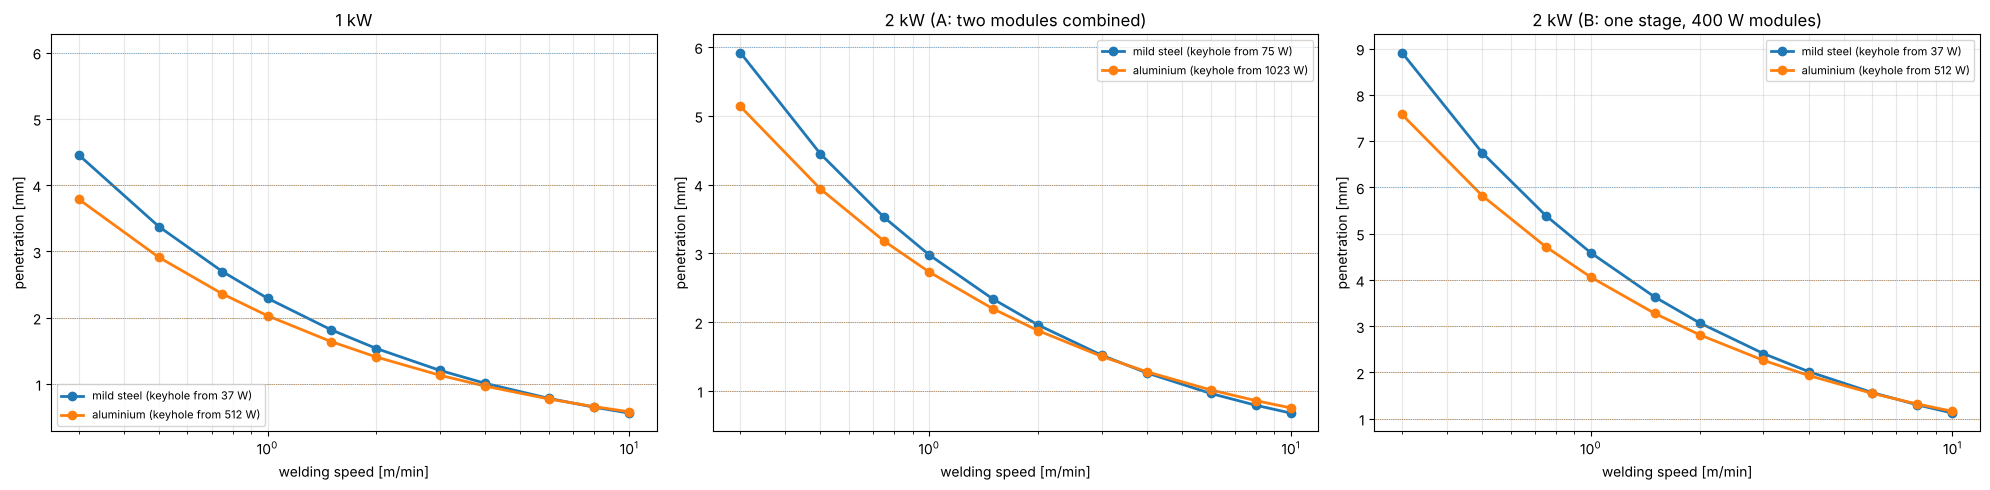

In [25]:
WELD = {k: DEV[k].welds(ST[k]["delivered_W"]) for k in ("1kW", "2kW", "2kW-B")}
for k, w in WELD.items():
    print(f"{DEV[k].name}: keyhole thresholds", {m: f"{d['keyhole']['P_threshold_W']:.0f} W" for m, d in w.items()})
PEN = pd.concat({DEV[k].name: pd.DataFrame({m: dict(zip([f"{v * 60:g} m/min" for v in si.SPEEDS], (d["curve"]["depth"] * 1e3).round(2))) for m, d in w.items()}).T for k, w in WELD.items()})
display(PEN)
WIN = pd.concat({(DEV[k].name, m): pd.DataFrame(d["window"]).assign(**{"thickness [mm]": lambda x: x["thickness"] * 1e3, "v full [m/min]": lambda x: x["v_full_penetration"] * 60,
                                                                       "v margin [m/min]": lambda x: x["v_with_margin"] * 60})[["thickness [mm]", "v full [m/min]", "v margin [m/min]", "feasible"]]
                 for k, w in WELD.items() for m, d in w.items()}); display(WIN.round(2))
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for ax, k in zip(axs, WELD):
    sid.penetration_view(WELD[k], {n: [t * 1e3 for t in m["thicknesses"]] for n, m in si.WELD_MATERIALS.items()}, ax=ax); ax.set_title(DEV[k].name)
plt.tight_layout(); plt.savefig(OUT / "welds.png", dpi=110); plt.show()

# Part IV — the guard, for both devices

A laser guard is judged on the worst beam it can meet for a stated time (IEC 60825-4: T1 10 s, T2 100 s, T3 30 000 s).
The method with the biggest return per second of computing: closed forms screen every (barrier, beam) pair, a cheap steady
solve settles the ambiguous ones, the transient conduction/ablation solver runs only where the steady state melts.
Each topic runs the 1 kW and the 2 kW devices in turn.

### 1. The stray beams at 20 m

The raw collimated beam (escaping before the focusing optic, or re-collimated by a reflector — the full power in a beam
that grows only by the process fibre's divergence r_core/f_c), the beam diverging past the focus (metres wide, harmless
to materials), a keyhole back-reflection (a fifth of the power, diverging).

power [W]  radius at 20 m [mm]  irradiance [W/cm²]
1 kW                           raw collimated beam          933.25                 17.0              102.79
                               diverging past the focus     933.25               1200.0                0.02
                               keyhole back-reflection      186.65               1200.0                0.00
2 kW (A: two modules combined) raw collimated beam         1810.51                 22.0              119.07
                               diverging past the focus    1810.51               1200.0                0.04
                               keyhole back-reflection      362.10               1200.0                0.01

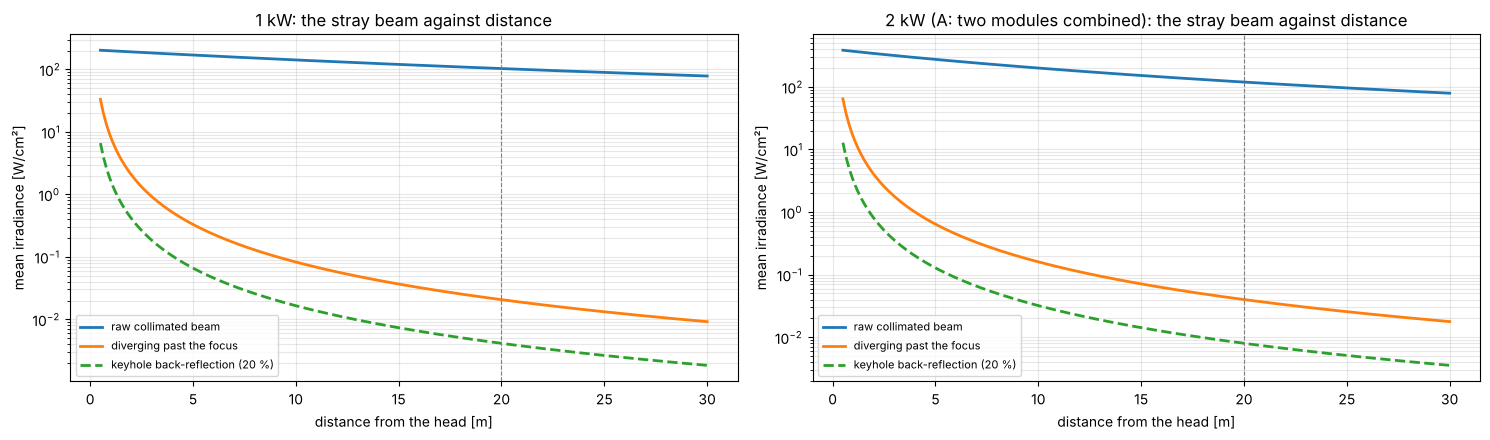

In [26]:
GD = {k: DEV[k] for k in ("1kW", "2kW")}
PW = {k: ST[k]["delivered_W"] for k in GD}
BEAMS = {k: d.stray_beams(PW[k]) for k, d in GD.items()}
display(pd.DataFrame({(d.name, b.name): {"power [W]": b.power, "radius at 20 m [mm]": b.radius * 1e3, "irradiance [W/cm²]": b.mean_irradiance / 1e4} for k, d in GD.items() for b in BEAMS[k]}).T.round(2))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (k, d) in zip(axs, GD.items()):
    sid.stray_view(BEAMS[k], d.head, d.delivery, PW[k], ax=ax); ax.set_title(f"{d.name}: the stray beam against distance")
plt.tight_layout(); plt.savefig(OUT / "stray.png", dpi=110); plt.show()

### 2. The barriers: screening, the simulations that decide, the verdict

Eleven barriers (black, clear and laser-grade polycarbonate at 5 and 10 mm, a 65 mm brick, aluminium at 1.5 and 3 mm,
mild steel at 1.5 and 3 mm) against the three beams, per device; the worst beam decides. The screening's decision per
pair, the transient only where it says *simulate*, the time each barrier holds against the classes.

66 pairs screened, 10 simulated in 91 s


holds [s] steady T_max [K]     T1     T2     T3                                 decided by
1 kW                           black polycarbonate 5 mm          13.119648     10017.871755   True  False  False  simulation: ablated through at the centre
                               black polycarbonate 10 mm         26.489194      9202.466022   True  False  False  simulation: ablated through at the centre
                               clear polycarbonate 5 mm                0.0              NaN  False  False  False                         fails: transparent
                               clear polycarbonate 10 mm               0.0              NaN  False  False  False                         fails: transparent
                               laser-safety polycarbonate 5 mm   13.676486      9779.867989   True  False  False  simulation: ablated through at the centre
                               laser-safety polycarbonate 10 mm  27.352972       8924.84061   True  False  False  simulation: ablated through at the centre
                               fired clay brick 65 mm                  inf     11957.274082   True   True   True                         simulation: steady
                               aluminium 1.5 mm                        inf              NaN   True   True   True                     survives: steady bound
                               aluminium 3 mm                          inf              NaN   True   True   True                     survives: steady bound
                               mild steel 1.5 mm                       inf      1221.625921   True   True   True                     survives: steady solve
                               mild steel 3 mm                         inf              NaN   True   True   True                     survives: steady bound
2 kW (A: two modules combined) black polycarbonate 5 mm          11.433641      15251.18564   True  False  False  simulation: ablated through at the centre
                               black polycarbonate 10 mm         22.651552     11181.109223   True  False  False  simulation: ablated through at the centre
                               clear polycarbonate 5 mm                0.0              NaN  False  False  False                         fails: transparent
                               clear polycarbonate 10 mm               0.0              NaN  False  False  False                         fails: transparent
                               laser-safety polycarbonate 5 mm   11.806477     14858.754772   True  False  False  simulation: ablated through at the centre
                               laser-safety polycarbonate 10 mm   23.39019     10845.531132   True  False  False  simulation: ablated through at the centre
                               fired clay brick 65 mm                  inf      13811.51941   True   True   True                         simulation: steady
                               aluminium 1.5 mm                        inf              NaN   True   True   True                     survives: steady bound
                               aluminium 3 mm                          inf              NaN   True   True   True                     survives: steady bound
                               mild steel 1.5 mm                       inf      1443.238201   True   True   True                     survives: steady solve
                               mild steel 3 mm                         inf      1254.338598   True   True   True                     survives: steady solve

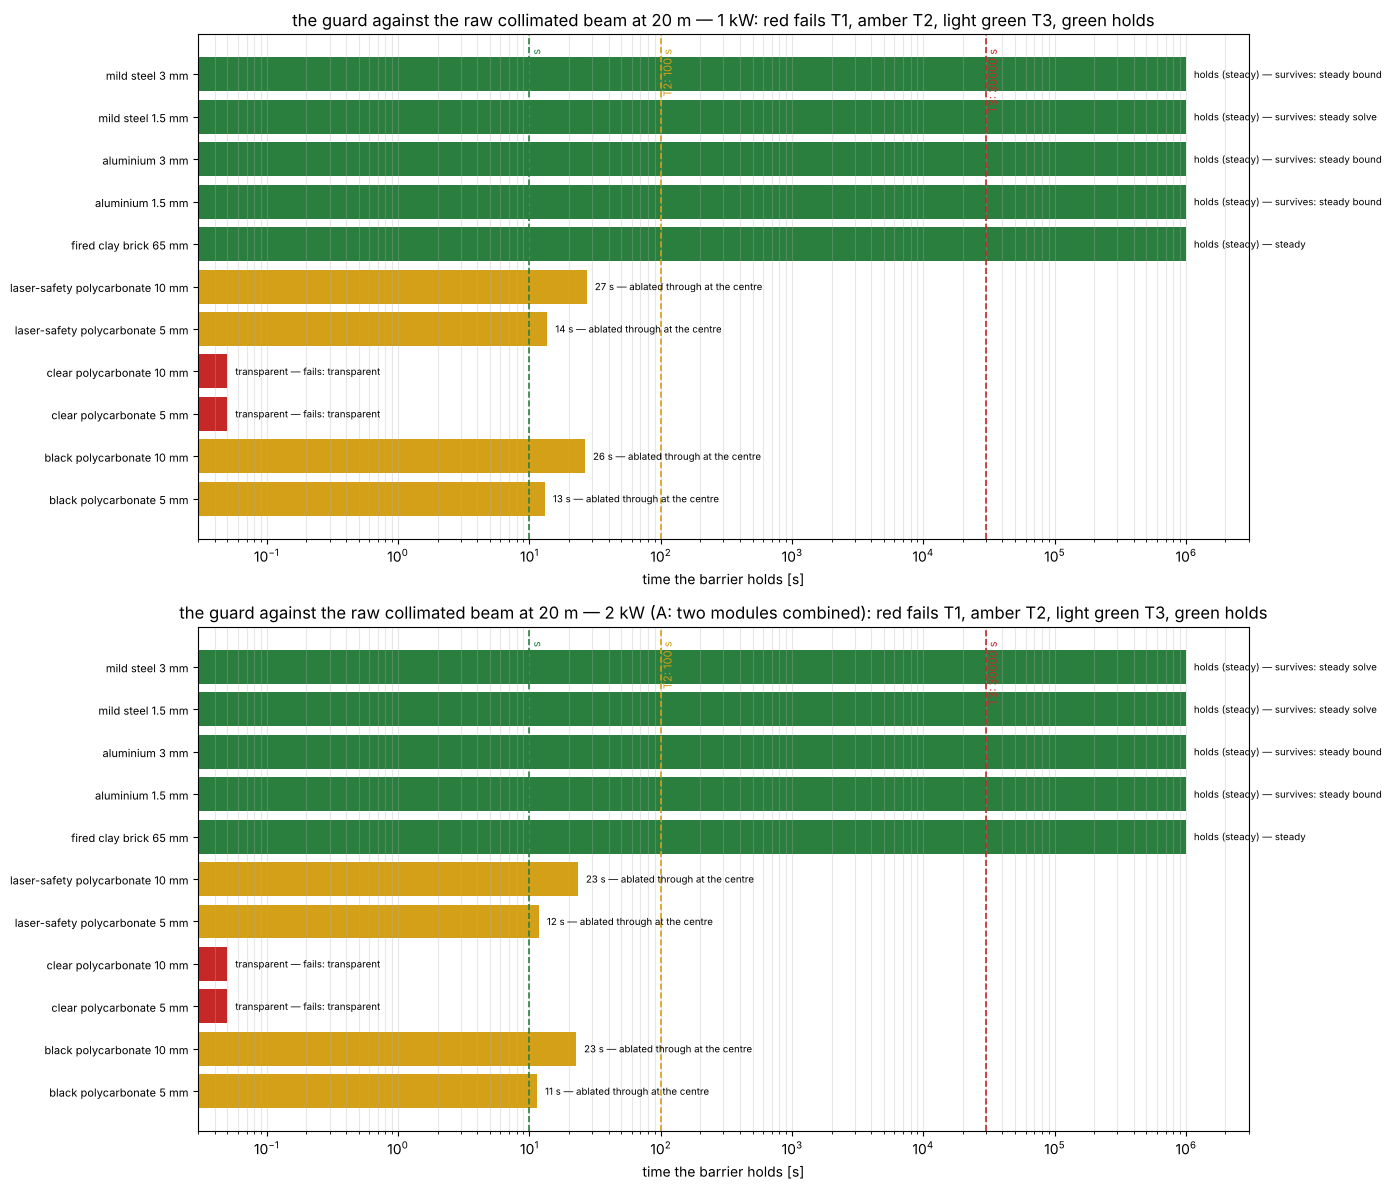

In [27]:
t0 = time.time()
G = {k: d.guard(PW[k]) for k, d in GD.items()}
print(f"{sum(len(g['rows']) for g in G.values())} pairs screened, {sum(sum(r['simulated'] for r in g['rows']) for g in G.values())} simulated in {time.time() - t0:.0f} s")
VER = pd.DataFrame({(GD[k].name, r["barrier"]): {"holds [s]": r["holds_s"], "steady T_max [K]": r["steady_T_max"], "T1": r["T1"], "T2": r["T2"], "T3": r["T3"], "decided by": r["source"]}
                    for k, g in G.items() for r in g["rows"] if r["beam"] == "raw collimated beam"}).T
display(VER.round(1))
fig, axs = plt.subplots(2, 1, figsize=(14, 12))
for ax, (k, g) in zip(axs, G.items()):
    sid.guard_timeline(g["rows"], si.EXPOSURE, ax=ax); ax.set_title(ax.get_title().replace("at 20 m", f"at 20 m — {GD[k].name}"))
plt.tight_layout(); plt.savefig(OUT / "verdict.png", dpi=110); plt.show()

### 3. The collimated beam against distance — the reference sheet

The reference wall: a **2 mm polycarbonate sheet, 1200 kg/m³, 60 × 60 cm** (black — a clear one passes the beam at any
distance), its edge the cold boundary, at 10, 20, 50, 100 and 200 m from each head. The irradiance falls as 1/r² with the
beam's growth (0.25 mrad for the 1 kW's fibre, 0.5 mrad for the 2 kW's) — but a 2 mm sheet has 2 mm to give.

beam_radius_mm  irradiance_W_per_cm2  absorbed_W_per_cm2  decision  surface_damage_s  holds_s     T1     T2     T3                                     source
                               distance_m                                                                                                                                                               
1 kW                           10.0                  14.5                141.29              134.23  simulate              0.07     3.78  False  False  False  simulation: ablated through at the centre
                               20.0                  17.0                102.79               97.65  simulate              0.10     5.25  False  False  False  simulation: ablated through at the centre
                               50.0                  24.5                 49.49               47.02  simulate              0.21    11.21   True  False  False  simulation: ablated through at the centre
                               100.0                 37.0                 21.70               20.61  simulate              0.47    27.70   True  False  False  simulation: ablated through at the centre
                               200.0                 62.0                  7.73                7.34  simulate              1.83   110.06   True   True  False  simulation: ablated through at the centre
2 kW (A: two modules combined) 10.0                  17.0                199.41              189.44  simulate              0.05     2.73  False  False  False  simulation: ablated through at the centre
                               20.0                  22.0                119.07              113.12  simulate              0.09     4.53  False  False  False  simulation: ablated through at the centre
                               50.0                  37.0                 42.10               39.99  simulate              0.24    13.42   True  False  False  simulation: ablated through at the centre
                               100.0                 62.0                 14.99               14.24  simulate              0.69    43.52   True  False  False  simulation: ablated through at the centre
                               200.0                112.0                  4.59                4.36  simulate              3.65      inf   True   True   True                         simulation: steady

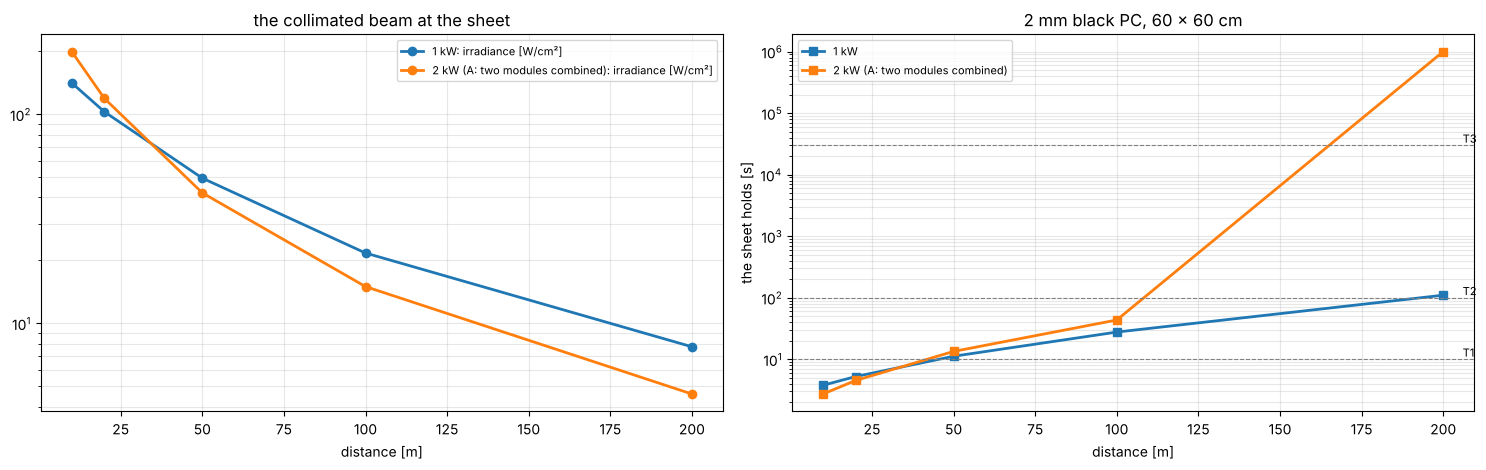

In [28]:
DIST = {k: d.distance(PW[k]) for k, d in GD.items()}
DT = pd.concat({GD[k].name: pd.DataFrame([{kk: v for kk, v in r.items() if kk != "simulation"} for r in rows]).set_index("distance_m") for k, rows in DIST.items()})
display(DT.round(2))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
for k, rows in DIST.items():
    dd = [r["distance_m"] for r in rows]
    axs[0].semilogy(dd, [r["irradiance_W_per_cm2"] for r in rows], "o-", lw=2, label=f"{GD[k].name}: irradiance [W/cm²]")
    axs[1].semilogy(dd, [min(r["holds_s"], 1e6) if r["holds_s"] > 0 else 0.05 for r in rows], "s-", lw=2, label=GD[k].name)
axs[0].set_xlabel("distance [m]"); axs[0].legend(fontsize=8); axs[0].grid(alpha=0.3, which="both"); axs[0].set_title("the collimated beam at the sheet")
for cls, t in si.EXPOSURE.items():
    axs[1].axhline(t, color="grey", ls="--", lw=0.8); axs[1].text(205, t, f" {cls}", fontsize=8, va="bottom")
axs[1].set_xlabel("distance [m]"); axs[1].set_ylabel("the sheet holds [s]"); axs[1].legend(fontsize=8); axs[1].grid(alpha=0.3, which="both"); axs[1].set_title("2 mm black PC, 60 × 60 cm")
plt.tight_layout(); plt.savefig(OUT / "distance.png", dpi=110); plt.show()

### 4. What the air takes on the way

At 1070 nm the molecules take nothing over 200 m; aerosols do, by the Kruse–Kim law on the day's visibility, and fog's
droplets scatter regardless of wavelength. Four days: clear (40 km visibility), wet (8 km), a dusty town (4 km), a foggy
autumn morning (300 m). The verdicts above are for a clear day — the worst case for the guard; fog is the only air that
takes more than a few per cent, and nobody welds in it.

loss [dB/km]  arrives at 10 m [W]  arrives at 20 m [W]  arrives at 50 m [W]  arrives at 100 m [W]  arrives at 200 m [W]  lost at 10 m [%]  lost at 20 m [%]  lost at 50 m [%]  \
1 kW                           clear day                      0.2                932.8                932.3                930.9                 928.5                 923.8               0.1               0.1               0.3   
                               wet day                        1.0                931.1                928.9                922.3                 911.5                 890.3               0.2               0.5               1.2   
                               dusty town                     3.1                926.7                920.1                900.7                 869.3                 809.8               0.7               1.4               3.5   
                               foggy autumn morning          56.6                819.2                719.0                486.2                 253.3                  68.8              12.2              23.0              47.9   
2 kW (A: two modules combined) clear day                      0.2               1809.6               1808.7               1805.9                1801.3                1792.1               0.1               0.1               0.3   
                               wet day                        1.0               1806.2               1802.0               1789.3                1768.3                1727.1               0.2               0.5               1.2   
                               dusty town                     3.1               1797.7               1785.0               1747.4                1686.5                1571.0               0.7               1.4               3.5   
                               foggy autumn morning          56.6               1589.2               1394.9                943.3                 491.5                 133.4              12.2              23.0              47.9   

                                                     lost at 100 m [%]  lost at 200 m [%]  
1 kW                           clear day                           0.5                1.0  
                               wet day                             2.3                4.6  
                               dusty town                          6.8               13.2  
                               foggy autumn morning               72.9               92.6  
2 kW (A: two modules combined) clear day                           0.5                1.0  
                               wet day                             2.3                4.6  
                               dusty town                          6.8               13.2  
                               foggy autumn morning               72.9               92.6

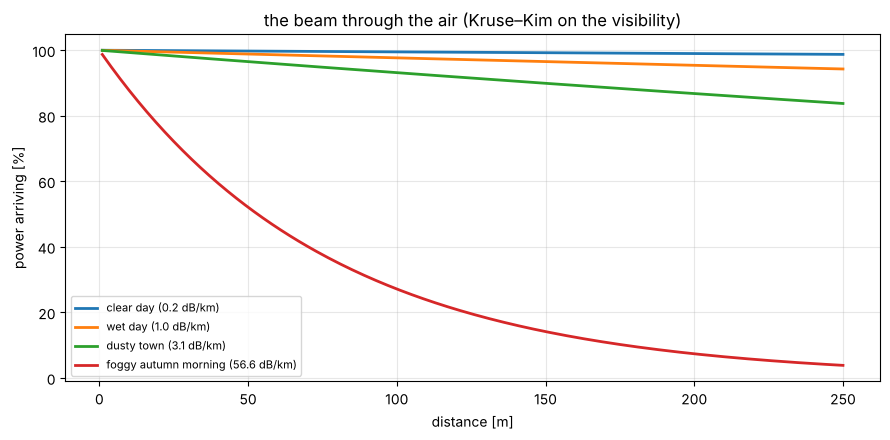

In [29]:
AIR = hy.transmission_table(si.DISTANCES, si.LAM)
AT = pd.concat({GD[k].name: pd.DataFrame({name: {"loss [dB/km]": a["db_per_km"], **{f"arrives at {int(d)} m [W]": PW[k] * t for d, t in a["transmission"].items()},
                                                 **{f"lost at {int(d)} m [%]": 100 * (1 - t) for d, t in a["transmission"].items()}} for name, a in AIR.items()}).T for k in GD})
display(AT.round(1))
fig, ax = plt.subplots(figsize=(9, 4.5)); dd = np.linspace(1, 250, 250)
for name, a in hy.ATMOSPHERES.items():
    ax.plot(dd, 100 * a.transmission(dd, si.LAM), lw=2, label=f"{name} ({a.loss_db_per_km(si.LAM):.1f} dB/km)")
ax.set_xlabel("distance [m]"); ax.set_ylabel("power arriving [%]"); ax.set_title("the beam through the air (Kruse–Kim on the visibility)"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "air.png", dpi=110); plt.show()

### 5. The same plates by finite elements — the fenix runs

Book **fenix** (`workflows/fenix/plate_thermal.py`) solves the same plates in FEniCSx in its own interpreter, one run
directory per chapter like any CFD or FEA chapter: F1 `guard-steady`, F2 `guard-ablation`, F3 `sheet-distance`, for
1kW and 2kW. This notebook takes the runs as optional inputs (auto mode makes them in screening quality when the
interpreter exists); the tables say NOT RUN otherwise. FEM against the cell model, per device.

In [30]:
def fenix(key):
    return GATE.inputs.get(key), GATE.selections.get(key)
slug = lambda name: name.replace(" ", "_").replace("-", "_").replace(".", "p")
for k, d in GD.items():
    v = d.variant
    FS, _ = fenix(f"fenix/guard-steady@{v}"); FA, FAD = fenix(f"fenix/guard-ablation@{v}"); FD, _ = fenix(f"fenix/sheet-distance@{v}")
    print(f"— {d.name}: guard-steady {'run' if FS else 'NOT RUN'}, guard-ablation {'run' if FA else 'NOT RUN'}, sheet-distance {'run' if FD else 'NOT RUN'}" + (f"  ({FA.get('fenicsx')}, {FA.get('quality')})" if FA else ""))
    rows = []
    for b in si.BARRIERS:
        scr = next(r for r in G[k]["rows"] if r["barrier"] == b.name and r["beam"] == "raw collimated beam"); sim = G[k]["simulations"].get((b.name, "raw collimated beam"))
        st = (FS or {}).get("cases", {}).get(slug(b.name), {}); ab = (FA or {}).get("cases", {}).get(slug(b.name), {})
        rows.append({"barrier": b.name, "numpy steady T_max [K]": scr["steady_T_max"], "FEM steady T_max [K]": st.get("T_max"), "numpy burn-through [s]": sim.failure_time if sim is not None else math.nan,
                     "FEM burn-through [s]": ab.get("failure_time"), "FEM status": (ab or st).get("status", "NOT RUN")})
    display(pd.DataFrame(rows).set_index("barrier").round(1))
    if FD:
        display(pd.DataFrame({r["distance_m"]: {"numpy burn-through [s]": r["holds_s"], "FEM burn-through [s]": (FD["cases"].get(f"pc2mm_at_{int(r['distance_m'])}m") or {}).get("failure_time")} for r in DIST[k]}).T.round(1))

— 1 kW: guard-steady run, guard-ablation run, sheet-distance run  (dolfinx 0.11.0 (/home/user/mm/fenicsx/bin/python), screening)


,numpy steady T_max [K],FEM steady T_max [K],numpy burn-through [s],FEM burn-through [s],FEM status
barrier,,,,,
black polycarbonate 5 mm,10017.9,2131.8,13.1,14.8,solved
black polycarbonate 10 mm,9202.5,2180.1,26.5,31.8,solved
clear polycarbonate 5 mm,NaN,2114.1,NaN,NaN,solved
clear polycarbonate 10 mm,NaN,2161.3,NaN,NaN,solved
laser-safety polycarbonate 5 mm,9779.9,2114.1,13.7,15.6,solved
laser-safety polycarbonate 10 mm,8924.8,2161.3,27.4,32.4,solved
fired clay brick 65 mm,11957.3,2394.9,NaN,NaN,solved
aluminium 1.5 mm,NaN,420.3,NaN,NaN,solved
aluminium 3 mm,NaN,359.6,NaN,NaN,solved


,numpy burn-through [s],FEM burn-through [s]
10.0,3.8,4.3
20.0,5.2,5.6
50.0,11.2,12.2
100.0,27.7,25.6
200.0,110.1,73.1


— 2 kW (A: two modules combined): guard-steady run, guard-ablation run, sheet-distance run  (dolfinx 0.11.0 (/home/user/mm/fenicsx/bin/python), screening)


,numpy steady T_max [K],FEM steady T_max [K],numpy burn-through [s],FEM burn-through [s],FEM status
barrier,,,,,
black polycarbonate 5 mm,15251.2,2213.9,11.4,12.4,solved
black polycarbonate 10 mm,11181.1,2221.7,22.7,27.8,solved
clear polycarbonate 5 mm,NaN,2195.8,NaN,NaN,solved
clear polycarbonate 10 mm,NaN,2203.6,NaN,NaN,solved
laser-safety polycarbonate 5 mm,14858.8,2195.8,11.8,13.0,solved
laser-safety polycarbonate 10 mm,10845.5,2203.6,23.4,28.3,solved
fired clay brick 65 mm,13811.5,2626.6,NaN,NaN,solved
aluminium 1.5 mm,NaN,527.1,NaN,NaN,solved
aluminium 3 mm,NaN,418.3,NaN,NaN,solved


,numpy burn-through [s],FEM burn-through [s]
10.0,2.7,2.8
20.0,4.5,5.3
50.0,13.4,13.7
100.0,43.5,37.0
200.0,inf,136.4


# Part V — the record, and reading it

Part I's and Part II's records are already on disk (`svarog_design.json`, `svarog_fiber_design.json`); here the industrial
record (`svarog_industrial_design.json`: the 1 kW device as Hyperion objects) and the one report of the whole notebook,
`reports/46_svarog.json` — Part I's keys at the top level, then `fibre`, `industrial` (per device: the stage, the budget,
the head, the welds), `guard` (per device: beams, verdicts, distance, fenix) and `air`. The fenix book reads
`industrial.<variant>.delivered_W` from it; the exit gate stamps every file.

In [31]:
def _j(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    if hasattr(o, "to_dict"):
        return o.to_dict()
    if isinstance(o, float) and not math.isfinite(o):
        return None if math.isnan(o) else ("inf" if o > 0 else "-inf")
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return str(o)

IND_REC = si.design_record(ST["1kW"]["length"], SEED, ST["1kW"]["pump_W"], ST["1kW"]["sol"], ST["1kW"]["budget"], WELD["1kW"], {"beams": BEAMS["1kW"], "rows": G["1kW"]["rows"]})
hy.save_design(DATA / "svarog_industrial_design.json", IND_REC, notes="Svarog-industrial: the 1 kW device (notebook 46 Part III)")
REPORT = {**ROD_REPORT, "meta": {**ROD_REPORT["meta"], "notebook": "46_svarog", "parts": ["rod", "fibre", "industrial", "guard"], "debug": DEBUG},
          "fibre": FIBRE_REPORT,
          "industrial": {DEV[k].variant if k != "2kW-B" else "2kW-B": {"name": DEV[k].name, "delivered_W": ST[k]["delivered_W"], "stage": STAGE.loc[DEV[k].name].to_dict(), "budget": BUDGET.loc[DEV[k].name].to_dict(),
                                                                        "head": HN.get(k), "welds": {m: {"keyhole": w["keyhole"], "window": w["window"]} for m, w in WELD[k].items()}} for k in DEV},
          "guard": {DEV[k].variant: {"power_W": PW[k], "beams": [vars(b) for b in BEAMS[k]], "verdicts": [{kk: v for kk, v in r.items()} for r in G[k]["rows"]],
                                     "distance": {r["distance_m"]: {kk: v for kk, v in r.items() if kk != "simulation"} for r in DIST[k]},
                                     "fenix": {c: GATE.selections.get(f"fenix/{c}@{DEV[k].variant}") for c in ("guard-steady", "guard-ablation", "sheet-distance")}} for k in GD},
          "air": {name: a for name, a in AIR.items()}}
(DATA / "reports").mkdir(parents=True, exist_ok=True)
(DATA / "reports" / "46_svarog.json").write_text(json.dumps(REPORT, indent=1, default=_j))
print("written", DATA / "svarog_industrial_design.json", "and", DATA / "reports" / "46_svarog.json")

written designs/data/svarog_industrial_design.json and designs/data/reports/46_svarog.json


In [32]:
STAMPS = GATE.leave()          # every record, written by this run and stamped

### Reading it

- **The rod taught the physics, the fibre is the device.** The rod's design was the fight between the pump's thermal lens
  and the cavity's window (Magni's rule); the fibre has no lens and no alignment — its design is a length and two gratings,
  and a kilowatt is one more stage of the same rate equations, cooled on a water spool.
- **The 2 kW is two 1 kW modules** (route A): each runs as designed, the étendues add (M² 18, a 200 µm spot), the welds
  land between the 1 kW's and route B's 100 µm spot; route B keeps the spot and pays with 220 W of heat on one spool and an
  SRS margin of a few times.
- **The guard is the collimated beam's**: clear polycarbonate is no guard at 1 µm; black and dyed sheets hold T1 only;
  metals hold by conduction (1.5 mm steel at ~1250 K under 1 kW, ~1440 K under 2 kW — never molten); brick melts at the
  surface and stalls. The reference 2 mm sheet fails T1 inside 20 m of either head, holds T1 from 50 m, T2 only at 200 m.
  The air changes none of it on a working day (≤ 1 % clear, 13 % in a dusty town at 200 m); fog takes 93 %.
- **The finite elements agree with the cell model** within 1 % on steady states and 10–20 % on burn-through times — and
  disagree on the one marginal case (the 2 kW sheet at 200 m: steady in one, through at 136 s in the other), which is the
  standard's test to decide.